# The circuit behind Qwen3-8B's algorithm choice (K3): a CPU replay of `method.py`

**Question.** When Qwen3-8B (bf16, thinking off) writes a program for a graph task, a single token decides which
algorithm it writes. For **B3 (minimum spanning tree weight)**, after a fixed 61-token opening that ends in
`graph[v].append((u, w))\n\n    #`, the next token is ` Kr` (Kruskal) or ` Prim`. Which components inside the model
compute that choice? And does steering them change the algorithm the model actually writes?

**The original pipeline** (`method.py`, about 8,500 GPU-seconds on one NVIDIA L4) runs in stages:

| stage | what it does | needs the 8B model |
|---|---|---|
| `setup` | hardware, tokenizer asserts, CPU unit tests, pre-registration commit #0 | partly |
| `contrasts` | clean/corrupt prompt pairs and their total effect on m = z(' Kr') - z(' Prim') | yes |
| `amend0a` | committed fallback rules (F2: C1-forced becomes the primary contrast) | no |
| `circuit:X` | attribution-patching (AtP) screen of 4,752 nodes, exact noising/denoising, path patching | yes |
| `f4b:X` | exhaustive exact sweep over all decision-position and MLP nodes, re-ranking | yes |
| `commit1` | frozen top-10, write-norm-matched random components, RAND5 | partly |
| `validate:X` | ABLATE / STEER each top-10 node vs 50 matched random components | yes |
| `gen:X`, `dose:X` | steer five components while the model writes programs; label and test them | yes |
| `validation_stats`, `gen_stats`, `dose_stats` | sign-flip tests, Holm, exact McNemar, K3 criteria | no |

**What this notebook does.** A forward pass of Qwen3-8B needs about 16.4 GB of GPU memory (18.4 GB with gradients).
A free Colab GPU or a CPU can't provide that within a 10-minute demo. So the notebook **replays the CPU side of
`method.py` on the outputs its GPU stages recorded** for the primary unit (B3, contrast **C1forced**). The
original functions run as written. Each model call is replaced by the array that call produced in the original run;
those lines are marked `# [replay]`. At the end, 17 headline numbers of the replay are checked against the values the
original run reported.

In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru: NOT pre-installed on Colab, always install (method.py logs through it)
_pip('loguru==0.7.3')

# numpy, scipy, statsmodels, pandas, matplotlib: pre-installed on Colab, install locally only (Colab's versions)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'statsmodels==0.14.6', 'pandas==2.2.2', 'matplotlib==3.10.0')

In [2]:
from __future__ import annotations

import argparse
import gc
import json
import sys
import time
from pathlib import Path
from typing import Any

import numpy as np
# import torch                  # [notebook] only the GPU stages use torch; the CPU replay does not need it
from loguru import logger

# [notebook] method.py put src/ on the path and imported the project modules:
#   sys.path.insert(0, str(Path(__file__).resolve().parent / "src"))
#   import k3circuit as KC, k3engine as EN, k3prompts as KP, k3stats as KS; from k3cfg import (...)
# The CPU parts of k3cfg / k3stats / k3circuit are copied into the "Helper modules" cells below. k3engine (model
# loading, edit hooks, generation) and k3prompts (prompt construction) only serve the GPU stages.

# [notebook] additions for the replay, the tables and the plots
import hashlib
import shutil
from datetime import datetime, timezone
from types import SimpleNamespace

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.float_format", lambda v: f"{v:.4g}")
pd.set_option("display.max_colwidth", 120)

In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-8/experiment-41/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            d = json.loads(response.read().decode())
        if isinstance(d, dict) and "recorded" in d:
            return d
        # [notebook] an older demo file can sit at this URL until this version is published
        print("GitHub data has a different layout, using local mini_demo_data.json")
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")

In [4]:
data = load_data()
rec = data["recorded"]                         # recorded GPU outputs of the original run
examples = data["datasets"][0]["examples"]     # the 60 generation slots of B3 / C1forced
print(data["metadata"]["model"])
print(data["datasets"][0]["dataset"], "-", len(examples), "examples")
for k, v in data["metadata"]["recorded_from"].items():
    print(f"  {k:30s} <- {v}")

GitHub data has a different layout, using local mini_demo_data.json
Qwen/Qwen3-8B@b968826d (bf16, thinking off)
B3_mst_weight_C1forced_generation - 60 examples
  contrasts                      <- results/contrasts.json (C1-nat pair sets A/B, held-out, C1-forced; C2a omitted)
  gpu_tests                      <- results/gpu_tests.json (U1, U3, U3b, U9)
  circuit_C1forced               <- results/circuit_C1forced.json (pairs, screen stats, rankings, path-patching edges, per-pair faithfulness rows)
  arrays_C1forced                <- cache/exact_C1forced.npz, cache/f4b_C1forced.npz, cache/atp_C1forced.npz (mean over pairs + per-pair values of the exact-measured nodes, 8 significant digits), cache/atpig_C1forced.npz (160 reliability nodes)
  write_norms_C1forced           <- cache/write_norms_C1forced.npy
  selection_C1forced             <- results/selection_C1forced.json (commit #1; class-mean hashes dropped)
  validation_rows_C1forced       <- data/validation_rows_C1forced.jsonl (30 promp

## Configuration

The replayed computations are cheap. The test of each node against its random null, the McNemar comparisons and the
re-ranking finish in seconds. So the parameters below are set to the **original values** of the run. Smaller values
give a quicker but noisier replay, and the check table at the end then shows where the numbers differ from the
recorded ones.

* `MAX_PROMPTS`: validation prompts replayed, in run order (`method.py --max-prompts`; original `None` = all 30:
  20 pair prompts + 10 held-out).
* `N_RAND`: matched random components per node in the validation null (original 50). It also bounds the RAND5 draw.
* `GEN_SLOTS`: common-random-number (CRN) slots per template W1-W5 in generation (original `range(6)`, so N = 30
  programs per arm).

The other constants are the design values fixed in commit #0 (copied from `src/k3cfg.py`).

In [5]:
# ---------------- tunable parameters (original values; the first test run used 6 / 5 / range(1))
MAX_PROMPTS = None              # validation prompts replayed (None = all 30, as in the original run)
N_RAND = 50                     # matched random components per node in the null (original: 50)
GEN_SLOTS = tuple(range(6))     # CRN slots per template (original: tuple(range(6)) -> N = 30 per arm)

NAME = "C1forced"               # the contrast replayed (primary C1 unit; the one in mini_demo_data.json)
ROOT = Path("k3_replay")        # [notebook] stands in for the artifact directory (data/, results/, cache/, ...)

# ---------------- design constants (src/k3cfg.py, fixed in commit #0)
N_LAYERS = 36
N_HEADS = 32
HEAD_DIM = 128
CLASSES = ("COND", "SPEC", "OPEN", "DEC")
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
SEED_HELDOUT = 8301
SEED_POOL = 8302
SEED_RAND5 = 8303
SEED_REL = 8304
SEED_CAL = 8305
N_TOP_EXACT = 60
N_CAL = 20
N_REL_PER_CLASS = 40
N_EDGE = 15
N_VAL = 10
KS_FAITH = (5, 10, 15, 30, 60)
STEER_DOSE = 2.0
TE_MIN = 0.2
EDGE_FRAC = 0.05
ATP_SPEARMAN_MIN = 0.6
GEN_THRESH_PLUS = 6
GEN_PASS_RATIO = 0.8
MAX_NEW_GEN = 1024

## Helper modules (copied from `src/`)

`method.py` imports four project modules. The parts the CPU replay needs are copied here unchanged:

* **k3cfg**: paths, JSON / JSONL I/O, deviation log, stage timing. Paths now live under `k3_replay/`, which is
  emptied on every run.
* **k3stats**: the exact one-sided sign-flip permutation test (all 2^n sign patterns by meet-in-the-middle, n ≤ 40),
  Holm, the exact McNemar test, and the Wilson and Newcombe intervals.
* **k3circuit**: the 4,752-node set (36 layers × (32 heads + 1 MLP) × 4 position classes), node keys and the
  write-norm-matched random pools.

`KC` and `KS` are plain namespaces, so the `method.py` code below keeps its `KC.` / `KS.` calls.

In [6]:
# ---------------- from src/k3cfg.py (paths now under ROOT)
shutil.rmtree(ROOT, ignore_errors=True)        # [notebook] every run replays into an empty directory
SRC = ROOT / "src"
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
LOG_DIR = ROOT / "logs"
PRED_DIR = ROOT / "predictions"
CACHE_DIR = ROOT / "cache"
for _d in (DATA_DIR, RESULTS_DIR, LOG_DIR, PRED_DIR, CACHE_DIR):
    _d.mkdir(parents=True, exist_ok=True)
COMMITS = ROOT / "commitments.log"


def setup_logging(name: str) -> None:
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")
    logger.add(str(LOG_DIR / f"{name}.log"), rotation="30 MB", level="DEBUG")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def sha256_text(s: str) -> str:
    return hashlib.sha256(s.encode("utf-8")).hexdigest()


def sha256_file(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def _json_default(o: Any) -> Any:
    if isinstance(o, np.integer):
        return int(o)
    if isinstance(o, np.floating):
        return None if not np.isfinite(o) else float(o)
    if isinstance(o, np.ndarray):
        return o.tolist()
    if isinstance(o, np.bool_):
        return bool(o)
    if isinstance(o, Path):
        return str(o)
    if isinstance(o, (set, frozenset)):
        return sorted(o)
    if isinstance(o, tuple):
        return list(o)
    raise TypeError(f"not JSON serialisable: {type(o)}")


def read_json(p: Path) -> Any:
    return json.loads(Path(p).read_text())


def write_json(p: Path, obj: Any) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    tmp.write_text(json.dumps(obj, indent=1, default=_json_default))
    tmp.replace(p)


def read_jsonl(p: Path) -> list[dict[str, Any]]:
    p = Path(p)
    if not p.exists():
        return []
    out = []
    with open(p) as fh:
        for line in fh:
            line = line.strip()
            if line:
                try:
                    out.append(json.loads(line))
                except json.JSONDecodeError:
                    logger.warning(f"skipping malformed line in {p.name}")
    return out


def append_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    with open(p, "a") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
        fh.flush()


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    p = Path(p)
    p.parent.mkdir(parents=True, exist_ok=True)
    tmp = p.with_suffix(p.suffix + ".tmp")
    with open(tmp, "w") as fh:
        for r in rows:
            fh.write(json.dumps(r, default=_json_default) + "\n")
    tmp.replace(p)


def log_deviation(dev_id: str, text: str, severity: str = "minor") -> None:
    p = RESULTS_DIR / "deviations.json"
    cur = read_json(p) if p.exists() else []
    if any(d["id"] == dev_id for d in cur):
        return
    cur.append({"id": dev_id, "severity": severity, "text": text, "utc": utc_now()})
    write_json(p, cur)
    logger.warning(f"DEVIATION {dev_id}: {text}")


def stage_time(stage: str, seconds: float, **extra: Any) -> None:
    append_jsonl(RESULTS_DIR / "stage_timing.jsonl", [{"stage": stage, "seconds": round(seconds, 1), "utc": utc_now(),
                                                       **extra}])


setup_logging("method")

In [7]:
# ---------------- from src/k3stats.py (unchanged)
import math

from scipy.stats import binom, norm


def _half_sums(d: np.ndarray) -> np.ndarray:
    n = len(d)
    if n == 0:
        return np.zeros(1)
    idx = np.arange(1 << n, dtype=np.int64)
    signs = ((idx[:, None] >> np.arange(n, dtype=np.int64)[None]) & 1) * 2 - 1
    return signs @ d


def sign_flip_p(d: np.ndarray, n_mc: int = 1_000_000, seed: int = 0, exact_max: int = 40) -> float:
    """One-sided p for mean(d) > 0 under random sign flips: exact enumeration of all 2^n patterns by meet-in-the-middle
    (sums of the two halves, sorted, counted with searchsorted) for n <= exact_max, else n_mc Monte Carlo flips."""
    d = np.asarray(d, dtype=np.float64)
    n = len(d)
    if n == 0:
        return 1.0
    obs = d.sum()
    tol = 1e-9 * max(1.0, float(np.abs(d).sum()))
    if n <= exact_max:
        h = n // 2
        a = _half_sums(d[:h])
        b = np.sort(_half_sums(d[h:]))
        ge = 0
        for c0 in range(0, len(a), 1 << 16):
            ac = a[c0:c0 + (1 << 16)]
            ge += int((len(b) - np.searchsorted(b, obs - ac - tol, side="left")).sum())
        return ge / float(1 << n)
    rng = np.random.default_rng(seed)
    ge = 0
    done = 0
    while done < n_mc:
        m = min(100_000, n_mc - done)
        signs = rng.integers(0, 2, size=(m, n)) * 2 - 1
        ge += int((signs @ d >= obs - tol).sum())
        done += m
    return (ge + 1) / (n_mc + 1)


def holm(ps: list[float]) -> list[float]:
    m = len(ps)
    order = np.argsort(ps)
    adj = np.zeros(m)
    run = 0.0
    for r, i in enumerate(order):
        run = max(run, (m - r) * ps[i])
        adj[i] = min(1.0, run)
    return adj.tolist()


def mcnemar_exact(b: int, c: int, alternative: str = "greater") -> float:
    """b = discordant pairs favouring the first arm, c = favouring the second. One-sided (first > second) or two-sided
    exact binomial p."""
    n = b + c
    if n == 0:
        return 1.0
    if alternative == "greater":
        return float(binom.sf(b - 1, n, 0.5))
    p = 2 * min(binom.cdf(b, n, 0.5), binom.sf(b - 1, n, 0.5))
    return float(min(1.0, p))


def wilson(k: int, n: int, a: float = 0.05) -> tuple[float, float]:
    if n == 0:
        return (0.0, 1.0)
    z = norm.ppf(1 - a / 2)
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe_paired(a: int, b: int, c: int, d: int, alpha: float = 0.05) -> dict[str, float]:
    """Newcombe (1998) method 10 for theta = p1 - p2 from paired binary data: a = both 1, b = 1/0, c = 0/1, d = both 0."""
    n = a + b + c + d
    if n == 0:
        return {"diff": 0.0, "lo": -1.0, "hi": 1.0}
    p1, p2 = (a + b) / n, (a + c) / n
    l1, u1 = wilson(a + b, n, alpha)
    l2, u2 = wilson(a + c, n, alpha)
    theta = p1 - p2
    num = a * d - b * c
    den = math.sqrt((a + b) * (c + d) * (a + c) * (b + d)) if (a + b) * (c + d) * (a + c) * (b + d) > 0 else 0.0
    if den == 0:
        phi = 0.0
    else:
        phi = (max(num - n / 2, 0) if num > 0 else num) / den
    dl = math.sqrt(max(0.0, (p1 - l1) ** 2 - 2 * phi * (p1 - l1) * (u2 - p2) + (u2 - p2) ** 2))
    du = math.sqrt(max(0.0, (u1 - p1) ** 2 - 2 * phi * (u1 - p1) * (p2 - l2) + (p2 - l2) ** 2))
    return {"diff": theta, "lo": max(-1.0, theta - dl), "hi": min(1.0, theta + du)}


def rule_of_three(n: int) -> float:
    return 3.0 / n if n > 0 else 1.0


def spearman_pearson(a: np.ndarray, b: np.ndarray) -> dict[str, Any]:
    from scipy.stats import pearsonr, spearmanr

    a, b = np.asarray(a).ravel(), np.asarray(b).ravel()
    return {"spearman": float(spearmanr(a, b).statistic), "pearson": float(pearsonr(a, b).statistic),
            "mean_abs_err": float(np.abs(a - b).mean()), "mean_abs_exact": float(np.abs(b).mean()), "n": int(len(a))}


KS = SimpleNamespace(sign_flip_p=sign_flip_p, holm=holm, mcnemar_exact=mcnemar_exact, wilson=wilson,
                     newcombe_paired=newcombe_paired, rule_of_three=rule_of_three, spearman_pearson=spearman_pearson)

In [8]:
# ---------------- from src/k3circuit.py: the node set and the matched random pools (CPU parts, unchanged)
NPL = N_HEADS + 1                      # nodes per layer per class (32 heads + 1 MLP)
NN = len(CLASSES) * N_LAYERS * NPL     # 4,752


def all_nodes() -> list[tuple[str, int, int, str]]:
    out = []
    for c in CLASSES:
        for l in range(N_LAYERS):
            for h in range(N_HEADS):
                out.append(("head", l, h, c))
            out.append(("mlp", l, -1, c))
    return out


NODES = all_nodes()


def node_key(n: tuple) -> str:
    return f"{n[0]}|L{n[1]}|H{n[2]}|{n[3]}"


KEY2IDX = {node_key(n): i for i, n in enumerate(NODES)}


def parse_key(k: str) -> tuple[str, int, int, str]:
    kind, l, h, c = k.split("|")
    return kind, int(l[1:]), int(h[1:]), c


def select_random(top10: list[int], wn: np.ndarray, seed: int, n_rand: int = 50) -> dict[str, Any]:
    """Matched random components per top node: same type and position class, top-10 excluded. Heads: smallest
    tolerance on +-10% / +-25% / +-50% with >= 50 candidates, 50 drawn without replacement (else the nearest 50).
    MLPs: smallest tolerance on +-10% / +-25% / +-50% / nearest-10 with >= 10 distinct candidates, 50 draws with
    replacement, each draw's patch delta rescaled to the target's write norm."""
    rng = np.random.default_rng(seed)
    tops = set(top10)
    rand_sets: dict[str, list[str]] = {}
    factors: dict[str, list[float]] = {}
    matching: dict[str, Any] = {}
    for j in top10:
        nd = NODES[j]
        k = node_key(nd)
        pool = [i for i in range(NN) if NODES[i][0] == nd[0] and NODES[i][3] == nd[3] and i not in tops]
        w0 = wn[j]
        need = n_rand if nd[0] == "head" else 10
        tol, cand = None, []
        for t in (0.10, 0.25, 0.50):
            cand = [i for i in pool if abs(wn[i] - w0) <= t * max(w0, 1e-12)]
            if len(cand) >= need:
                tol = t
                break
        if tol is None:
            cand = sorted(pool, key=lambda i: abs(wn[i] - w0))[:need]
            tol = f"nearest-{need}"
        if nd[0] == "head":
            pick = rng.choice(len(cand), size=min(n_rand, len(cand)), replace=False)
            draws = [cand[i] for i in pick]
            fac = [1.0] * len(draws)
        else:
            pick = rng.choice(len(cand), size=n_rand, replace=True)
            draws = [cand[i] for i in pick]
            fac = [float(w0 / wn[d]) if wn[d] > 0 else 1.0 for d in draws]
        rand_sets[k] = [node_key(NODES[d]) for d in draws]
        factors[k] = fac
        matching[k] = {"tolerance": tol, "n_candidates": len(cand), "n_distinct_drawn": len(set(draws)),
                       "write_norm": float(w0), "draw_write_norm_mean": float(np.mean([wn[d] for d in draws])),
                       "rescale_factor_mean": float(np.mean(fac)), "rescale_factor_range": [float(min(fac)),
                                                                                           float(max(fac))]}
    return {"rand_sets": rand_sets, "factors": factors, "matching": matching}


KC = SimpleNamespace(NODES=NODES, NN=NN, KEY2IDX=KEY2IDX, node_key=node_key, parse_key=parse_key,
                     select_random=select_random)
print(f"{NN} nodes: {node_key(NODES[0])} ... {node_key(NODES[-1])}")

4752 nodes: head|L0|H0|COND ... mlp|L35|H-1|DEC


## Recorded GPU outputs → the artifact's file layout

The stages pass results to each other through files (`data/*.jsonl`, `results/*.json`, `cache/*.npz`). This cell
writes the recorded GPU outputs from `mini_demo_data.json` into the same layout under `k3_replay/`. The CPU functions
below then read the files they read in the original run.

* `cache/`: the exact-patching arrays (`exact_*.npz`: top 120 by |AtP| + 20 calibration + 160 reliability nodes;
  `f4b_*.npz`: the 1,171-node sweep), the AtP screen, and the write norms.
* `data/validation_rows_*.jsonl`: one row per prompt holding 1,224 metric changes Δm: 2 operations ×
  (10 nodes + 2 joint sets) × (the node + 50 random components).
* `data/gen_raw_*` / `gen_labels_*`: rebuilt from the 60 dataset examples, one row per arm (TWIN / TOP5 / RAND5)
  with its label, its hidden-test outcome and the program.

`MAX_PROMPTS` and `GEN_SLOTS` apply here, the same way `--max-prompts` and the slot list limited what the GPU
stages ran.

In [9]:
# [notebook] recorded GPU outputs that the original run kept in memory (no file of their own)
circ_rec = rec[f"circuit_{NAME}"]
GPU_REC = {"pairs": circ_rec["pairs"],                     # m_clean / m_corrupt of the 10 pairs (EN.collect)
           "edges_all": circ_rec["edges_all"],             # KC.edge_patching among the final top 15
           "faithfulness_rows": circ_rec["faithfulness"]}  # per-pair rows of faithfulness()

# cache/*.npz, *.npy as the GPU stages saved them
A = rec[f"arrays_{NAME}"]
np.savez_compressed(CACHE_DIR / f"exact_{NAME}.npz", **{k: np.array(v) for k, v in A["exact"].items()})
np.savez_compressed(CACHE_DIR / f"f4b_{NAME}.npz", **{k: np.array(v) for k, v in A["f4b"].items()})
atp = np.full((len(GPU_REC["pairs"]), NN), np.nan)        # per-pair AtP kept for the 1,468 exact-measured nodes
atp[:, A["atp_measured"]["nodes"]] = np.array(A["atp_measured"]["per_pair"])
np.savez_compressed(CACHE_DIR / f"atp_{NAME}.npz", atp=atp, atp_mean=np.array(A["atp_mean"]))
atp_ig = np.full_like(atp, np.nan)                        # IG-AtP kept for the 160 reliability nodes
atp_ig[:, A["exact"]["rel_nodes"]] = np.array(A["atp_ig_rel"])
np.savez_compressed(CACHE_DIR / f"atpig_{NAME}.npz", atp_ig=atp_ig)
np.save(CACHE_DIR / f"write_norms_{NAME}.npy", np.array(rec[f"write_norms_{NAME}"]))
write_json(RESULTS_DIR / "gpu_tests.json", rec["gpu_tests"])


def expand(block: dict[str, Any]) -> list[dict[str, Any]]:
    """Compact rows (one key list + one value list per prompt) -> the original {'res': {key: value}} rows."""
    return [{**{k: v for k, v in r.items() if k != "res_values"}, "res": dict(zip(block["res_keys"], r["res_values"]))}
            for r in block["rows"]]


# data/validation rows: the first MAX_PROMPTS prompts in run order (as --max-prompts), same prompts for the sensitivity
val_rows = expand(rec[f"validation_rows_{NAME}"])[:MAX_PROMPTS]
kept = {r["prompt_idx"] for r in val_rows}
write_jsonl(DATA_DIR / f"validation_rows_{NAME}.jsonl", val_rows)
write_jsonl(DATA_DIR / f"validation_sens_rows_{NAME}.jsonl",
            [r for r in expand(rec[f"validation_sens_rows_{NAME}"]) if r["prompt_idx"] in kept])

# data/gen_raw + gen_labels: one row per (example, arm), slots in GEN_SLOTS
gen_raw, gen_lab = [], []
for e in examples:
    if e["metadata_slot"] not in GEN_SLOTS:
        continue
    for arm in ("TWIN", "TOP5", "RAND5"):
        rid = f"{NAME}|{e['metadata_condition']}|{arm}|{e['metadata_template']}|{e['metadata_slot']}"
        label, outcome = e[f"predict_{arm}"].split("|")
        gen_raw.append({"row_id": rid, "contrast": NAME, "unit": e["metadata_unit"], "condition": e["metadata_condition"],
                        "arm": arm, "template": e["metadata_template"], "slot": e["metadata_slot"],
                        "reached_decision": e[f"metadata_{arm}_reached_decision"],
                        "n_new_tokens": e[f"metadata_{arm}_n_new_tokens"], "text": e[f"metadata_{arm}_code"]})
        gen_lab.append({"sid": rid, "unit": e["metadata_unit"], "label": label, "passed": outcome == "pass",
                        "code": e[f"metadata_{arm}_code"]})
write_jsonl(DATA_DIR / f"gen_raw_{NAME}.jsonl", gen_raw)
write_jsonl(DATA_DIR / f"gen_labels_{NAME}.jsonl", gen_lab)

# data/gen_dose_* (post-hoc dose sensitivity, PREFILL) and results/dose_logit
dose_raw = [r for r in rec[f"gen_dose_{NAME}"]["raw"] if r["slot"] in GEN_SLOTS]
dose_ids = {r["row_id"] for r in dose_raw}
write_jsonl(DATA_DIR / f"gen_dose_raw_{NAME}.jsonl", dose_raw)
write_jsonl(DATA_DIR / f"gen_dose_labels_{NAME}.jsonl", [r for r in rec[f"gen_dose_{NAME}"]["labels"]
                                                          if r["sid"] in dose_ids])
write_json(RESULTS_DIR / f"dose_logit_{NAME}.json", rec[f"dose_logit_{NAME}"])

for p in sorted(ROOT.rglob("*.*")):
    print(f"{str(p.relative_to(ROOT)):42s} {p.stat().st_size / 1e3:8.1f} kB")

cache/atp_C1forced.npz                        145.7 kB
cache/atpig_C1forced.npz                       17.3 kB
cache/exact_C1forced.npz                       17.6 kB
cache/f4b_C1forced.npz                         38.9 kB
cache/write_norms_C1forced.npy                 38.1 kB
data/gen_dose_labels_C1forced.jsonl            10.8 kB
data/gen_dose_raw_C1forced.jsonl               22.4 kB
data/gen_labels_C1forced.jsonl                183.1 kB
data/gen_raw_C1forced.jsonl                   201.8 kB
data/validation_rows_C1forced.jsonl          1775.3 kB
data/validation_sens_rows_C1forced.jsonl      467.7 kB
logs/method.log                                 0.0 kB
results/dose_logit_C1forced.json                6.4 kB
results/gpu_tests.json                          0.7 kB


## Stage `setup`: pre-registration (commit #0)

Before any contrast was measured, `stage_setup` wrote **commit #0**: the rules, thresholds and predictions P1-P5.
Each commit is chained by SHA-256 to the previous one in `commitments.log`, so a rule changed after the data was seen
would leave a trace. Amendment 0a, commit #1 and commit #2 follow below. The functions are unchanged except
`code_hashes()`, which now skips files that don't exist (the replay directory has no `src/` or `method.py`). The
hardware and tokenizer checks of `stage_setup` need the GPU and the tokenizer, so they are not replayed.

In [10]:
def commit(name: str, payload: dict[str, Any]) -> dict[str, Any]:
    prev = "0" * 64
    if COMMITS.exists():
        lines = [l for l in COMMITS.read_text().splitlines() if l.strip()]
        if lines:
            prev = lines[-1].split()[2]
    utc = utc_now()
    body = json.dumps({"name": name, "utc": utc, "prev": prev, "payload": payload}, sort_keys=True, default=str)
    h = sha256_text(body)
    write_json(PRED_DIR / f"{name}.json", {"name": name, "utc": utc, "prev": prev, "sha256": h, "payload": payload})
    with open(COMMITS, "a") as fh:
        fh.write(f"{utc} {name} {h} prev={prev}\n")
    logger.info(f"COMMIT {name}: {h[:16]} (prev {prev[:12]})")
    return {"sha256": h, "utc": utc}


def code_hashes() -> dict[str, str]:
    files = sorted((ROOT / "src").glob("*.py")) + [ROOT / "method.py"]
    return {str(p.relative_to(ROOT)): sha256_file(p) for p in files if p.exists()}   # [notebook] `if p.exists()`


def commit0_payload() -> dict[str, Any]:
    return {
        "claim": "K3: components that compute the odds of the decision token, validated in the real model",
        "model": "Qwen/Qwen3-8B@b968826d (bf16, thinking off, sdpa)",
        "node_set": "36 x 32 heads (o_proj input slice) + 36 MLP outputs at COND / SPEC / OPEN / DEC = 4,752 nodes",
        "metrics": {"C1": "m = z(' Kr') - z(' Prim') at DEC (last of B3's 61-token opening)",
                    "C2a": "m = z(' find') - z(' dfs') at DEC (' def', token 10 of the T10 prefix)",
                    "C2b": "m' = z(' find') - logsumexp(z(' dfs'), z(' bfs'))"},
        "pair_rule": "C1-nat: 24 neutral-noun variants per template W1-W5; within template the k-th highest m (clean) "
                     "with the k-th lowest (corrupt): set A k = 1..3, set B k = 4..6; held-out H 2 per template "
                     "(seed 8301, one above and one below the template median); pairs with TE <= 0.2 dropped; < 10 "
                     "surviving pairs or mean TE(A) < 1.0 nat -> F2 (C1-forced primary)",
        "screen": "AtP noising (grad at clean x (corrupt - clean)); top 60 by |mean AtP|; reliability: exact noising of "
                  "40 random nodes per class (seed 8304); Spearman < 0.6 -> IG-AtP (5 alphas) and 120 exact nodes",
        "exact": "noising and denoising of the top 60 + 20 random calibration nodes (seed 8305); ranking by |mean "
                 "noising effect| (Gemma's rule)",
        "edges": "path patching among the top 15; keep |mean| >= 0.05 x mean TE",
        "faithfulness": "k in {5,10,15,30,60}: clean input, non-circuit nodes frozen to corrupt values (type 1) or to "
                        "the corrupt-class same-template mean (type 2), circuit nodes live; completeness (top-k "
                        "noised) and sufficiency (top-k denoised)",
        "random_matching": "heads: +-10/25/50% write norm (>= 50 candidates), 50 without replacement; MLPs: "
                           "+-10/25/50%/nearest-10 (>= 10 distinct), 50 with replacement, delta rescaled to the "
                           "target's write norm; seed 8302",
        "validation": "ABLATE node <- opposite-class mean; STEER node <- own + 2 x (opposite mean - own mean); oriented "
                      "dm vs in-chunk base; d_i = dm_node - mean dm_rand; one-sided sign-flip (exact n <= 25 else "
                      "1e6 MC); PRIMARY Holm over all 20 node x test p; NODE PASS = Holm p < 0.05 in both tests; "
                      "Gemma's within-test Holm reported beside",
        "time_rule": "if the first-prompt timing extrapolates validation of one contrast beyond 45 min, V = 15 clean + "
                     "10 H; beyond that H drops to 5; random count never reduced (C1-nat)",
        "generation": "arms TWIN, TOP5 (STEER toward the minority on all five), RAND5 (frozen matched five, seed 8303); "
                      "N = 30 = W1-W5 x 6 CRN slots; T 1, top-p 1, no top-k, max_new 1024; PRIMARY = PREFILL "
                      "(prompt + opening prefilled for every arm); SECONDARY = FREE (OPEN/DEC edits fire only while "
                      "the generated prefix equals the opening); targets B3 correct prim_heap/prim_array, T10 correct "
                      "dfs",
        "gen_criteria": "TOP5 - TWIN correct-target >= 6; exact McNemar TOP5 vs RAND5 p < 0.05; pass(TOP5) >= 0.8 x "
                        "pass(TWIN)",
        "K3_verdict": "PASS = C1: >= 5 of 10 nodes pass both tests AND PREFILL top-5 meets all three generation "
                      "criteria; PARTIAL = exactly one; DISCONFIRMED = no top-10 node passes either test; C2a "
                      "reported with the same rule; the C1 McNemar p enters the paper's primary Holm family",
        "predictions": {"P1": ">= 5 of 10 nodes pass both tests on C1-nat",
                        "P2": "PREFILL top-5 steering: TWIN + >= 6 correct Prim of 30, beats RAND5 (McNemar p < "
                              "0.05), pass >= 0.8 x twin",
                        "P3": "the same on C2a toward DFS",
                        "P4": "motif: DEC share in [0.38, 0.68], COND share in [0.21, 0.51], DEC-position stack "
                              "effect-weighted depth in [0.45, 0.80]",
                        "P5": "top-10 Jaccard between pair sets A and B >= 0.4"},
        "motif_function": "share(c) = sum over the exact list (top 40 by |AtP| + 20 random calibration nodes, Gemma's "
                          "composition) in class c of |mean noising effect| / total; validated on Gemma's "
                          "g1_pathpatch.json (FORK 0.531, COND 0.357) before any Qwen value",
        "drop_order": ["transcoder extension", "C2b", "pair set B", "held-out beyond 5", "FREE condition rows"],
        "never_drop": ["C1 screen + exact + path patching + matched-random validation + PREFILL top-5 generation",
                       "C2a with validation", "motif test", "novelty audit"],
        "code_sha256": code_hashes(),
    }


if not COMMITS.exists() or "commit0" not in COMMITS.read_text():
    commit("commit0", commit0_payload())
print(json.dumps(read_json(PRED_DIR / "commit0.json")["payload"]["predictions"], indent=1))

18:27:14|INFO   |COMMIT commit0: 76577cf1c00be419 (prev 000000000000)


{
 "P1": ">= 5 of 10 nodes pass both tests on C1-nat",
 "P2": "PREFILL top-5 steering: TWIN + >= 6 correct Prim of 30, beats RAND5 (McNemar p < 0.05), pass >= 0.8 x twin",
 "P3": "the same on C2a toward DFS",
 "P4": "motif: DEC share in [0.38, 0.68], COND share in [0.21, 0.51], DEC-position stack effect-weighted depth in [0.45, 0.80]",
 "P5": "top-10 Jaccard between pair sets A and B >= 0.4"
}


### CPU unit tests (`cpu_tests`, part of `setup`)

These blocks check the statistical machinery the verdicts rest on. **T2**: the node set (4,752 nodes; keys
round-trip). **T4**: the exact sign-flip test against brute-force enumeration and against 10^6 Monte Carlo sign
flips. **T5**: Holm and the exact McNemar test against statsmodels and scipy. **T6**: the matched-random pool ladder on
synthetic write norms. T1 needs the tokenizer and the prompts, and T3 needs Gemma's result file; both passed in the
original run.

In [11]:
out: dict[str, Any] = {}
# T2 node keys
out["T2_n_nodes"] = len(KC.NODES)
out["T2_roundtrip"] = all(KC.parse_key(KC.node_key(n)) == n for n in KC.NODES)
# T4 sign flip
rng = np.random.default_rng(1)
d = rng.normal(0.3, 1, 10)
brute = np.mean([np.dot(np.array([1 if (k >> i) & 1 else -1 for i in range(10)]), d) >= d.sum() - 1e-12
                 for k in range(1 << 10)])
out["T4_exact_vs_brute"] = abs(KS.sign_flip_p(d) - brute) < 1e-12
d22 = rng.normal(0.2, 1, 22)
out["T4_exact_vs_mc"] = abs(KS.sign_flip_p(d22) - KS.sign_flip_p(d22, exact_max=0)) < 0.002
# T5 Holm / McNemar vs statsmodels / scipy
from statsmodels.stats.multitest import multipletests
ps = [0.01, 0.04, 0.03, 0.2, 0.001]
out["T5_holm"] = bool(np.allclose(KS.holm(ps), multipletests(ps, method="holm")[1]))
from scipy.stats import binomtest
out["T5_mcnemar"] = abs(KS.mcnemar_exact(8, 0) - binomtest(8, 8, 0.5, alternative="greater").pvalue) < 1e-12
out["T5_mcnemar_7_1"] = round(KS.mcnemar_exact(7, 1, "two-sided"), 4)
# T6 random pool ladder on synthetic norms
wn = np.abs(rng.normal(1, 0.3, KC.NN))
top = [5, 40, 1188 * 3 + 32]
sel = KC.select_random(top, wn, 0)
out["T6_pool"] = {k: (len(v), sel["matching"][k]["tolerance"]) for k, v in sel["rand_sets"].items()}
out["T6_pass"] = all(len(v) == 50 for v in sel["rand_sets"].values())
logger.info(f"CPU tests: {out}")

18:27:14|INFO   |CPU tests: {'T2_n_nodes': 4752, 'T2_roundtrip': True, 'T4_exact_vs_brute': np.True_, 'T4_exact_vs_mc': True, 'T5_holm': True, 'T5_mcnemar': np.True_, 'T5_mcnemar_7_1': 0.0703, 'T6_pool': {'head|L0|H5|COND': (50, 0.25), 'head|L1|H7|COND': (50, 0.1), 'mlp|L0|H-1|DEC': (50, 0.25)}, 'T6_pass': True}


## Stage `contrasts`: the decision token and its total effect

The metric is **m = z(' Kr') - z(' Prim')**, the logit difference at the decision position DEC (the last token of
B3's 61-token opening). It is read in fp32 from the final-norm hidden state. A contrast is a set of (clean, corrupt)
prompt pairs, and its total effect is **TE = m_clean - m_corrupt** in nats.

* **C1-nat**: 24 neutral-noun variants per template W1-W5 (`Do not use <noun> for this task.`). Within each
  template, the k-th highest-m variant (clean) is paired with the k-th lowest (corrupt): set A uses k = 1..3, set B
  uses k = 4..6.
* **C1-forced**: 10 forced-Prim paraphrases (`Implement Prim's algorithm ...`, corrupt) against their padding twins
  (clean).

The GPU part, teacher-forcing each prompt through Qwen3-8B (`EN.collect`), is replaced by stand-ins that carry the m
value and decision-token probabilities that call returned. The row building and the summary lines are the original
ones.

In [12]:
# [replay] stage_contrasts: `a_c = EN.collect(model, C.run_ids(c), C.metric)` ran each prompt through Qwen3-8B; the
# SimpleNamespace stand-ins carry the m value and the decision-token probabilities that call returned.
crec = rec["contrasts"]
out: dict[str, Any] = {}
out["C1nat_sd_m_v"] = crec["C1nat_sd_m_v"]            # was: read_json(RESULTS_DIR / "c1nat_variants.json")["sd_all"]
for which in ("A", "B"):
    rows = []
    for r0 in crec[f"C1nat_{which}"]["pairs"]:
        a_c = SimpleNamespace(m=r0["m_clean"], p_a=r0["p_kr_clean"], p_b=r0["p_prim_clean"])          # [replay]
        a_x = SimpleNamespace(m=r0["m_corrupt"], p_a=r0["p_kr_corrupt"], p_b=r0["p_prim_corrupt"])    # [replay]
        rows.append({"clean": r0["clean"], "corrupt": r0["corrupt"], "m_clean": a_c.m,
                     "m_corrupt": a_x.m, "TE": a_c.m - a_x.m, "p_kr_clean": a_c.p_a, "p_prim_clean": a_c.p_b,
                     "p_kr_corrupt": a_x.p_a, "p_prim_corrupt": a_x.p_b})
        del a_c, a_x
    te = [r["TE"] for r in rows]
    out[f"C1nat_{which}"] = {"pairs": rows, "TE_mean": float(np.mean(te)), "TE_sd": float(np.std(te)),
                             "n_TE_gt_min": int(sum(t > TE_MIN for t in te))}
    logger.info(f"C1nat {which}: TE mean {np.mean(te):.3f} (sd {np.std(te):.3f}); {sum(t > TE_MIN for t in te)}"
                f"/15 > {TE_MIN}")
out["C1nat_heldout"] = crec["C1nat_heldout"]
rows = []
for r0 in crec["C1forced"]["pairs"]:
    a_c = SimpleNamespace(m=r0["m_clean"])                                 # [replay]
    a_x = SimpleNamespace(m=r0["m_corrupt"], p_b=r0["p_prim_corrupt"])     # [replay]
    rows.append({"clean": r0["clean"], "corrupt": r0["corrupt"], "m_clean": a_c.m,
                 "m_corrupt": a_x.m, "TE": a_c.m - a_x.m, "p_prim_corrupt": a_x.p_b})
out["C1forced"] = {"pairs": rows, "TE_mean": float(np.mean([r["TE"] for r in rows]))}
# (the C2a replication contrast and its F3 fallback ladder are not part of this demo's data)
write_json(RESULTS_DIR / "contrasts.json", out)

print(f"SD of m over the 120 C1-nat variants: {out['C1nat_sd_m_v']:.3f} nats; "
      f"C1-forced mean TE: {out['C1forced']['TE_mean']:.2f} nats")
pd.DataFrame(out["C1nat_A"]["pairs"])

18:27:14|INFO   |C1nat A: TE mean 0.893 (sd 0.377); 15/15 > 0.2


18:27:14|INFO   |C1nat B: TE mean 0.393 (sd 0.186); 12/15 > 0.2


SD of m over the 120 C1-nat variants: 0.338 nats; C1-forced mean TE: 9.91 nats


,clean,corrupt,m_clean,m_corrupt,TE,p_kr_clean,p_prim_clean,p_kr_corrupt,p_prim_corrupt
0,W1|guy,W1|mother,1.23,0.6063,0.6239,0.7693,0.2204,0.6147,0.3728
1,W1|phone,W1|kid,1.23,0.8326,0.3975,0.772,0.2212,0.6701,0.3166
2,W1|office,W1|baby,1.038,0.7275,0.3108,0.724,0.2664,0.6706,0.3168
3,W2|coffee,W2|head,1.223,-0.1062,1.329,0.773,0.2215,0.4297,0.5518
4,W2|car,W2|school,1.439,0.2698,1.169,0.8132,0.1814,0.5528,0.4306
5,W2|phone,W2|dog,1.421,0.6373,0.7842,0.8134,0.1815,0.6718,0.3173
6,W3|car,W3|baby,1.778,0.1538,1.625,0.8457,0.147,0.493,0.493
7,W3|coffee,W3|kid,1.259,0.7746,0.4847,0.7724,0.2213,0.6722,0.3175
8,W3|school,W3|mother,1.55,0.8141,0.7355,0.811,0.181,0.6693,0.3162
9,W4|fire,W4|hand,1.615,0.5807,1.034,0.8131,0.1814,0.6155,0.3733


## Stage `amend0a`: committed fallbacks before any screen row

Commit #0 required a mean TE of at least 1 nat on C1-nat set A. The set gives **0.89 nats**, so fallback **F2** fires:
**C1-forced becomes the primary C1 unit**, and C1-nat is reported only descriptively. The same amendment decides
whether patching rows may reuse a cached prefix. GPU test U3 compares suffix forwards with full recomputation, and
U3b gives the bf16 noise floor across batch shapes. `stage_amend0a` runs unchanged and chains its commit onto
commit #0.

In [13]:
def stage_amend0a() -> None:
    c = read_json(RESULTS_DIR / "contrasts.json")
    g = read_json(RESULTS_DIR / "gpu_tests.json")
    te_a = c["C1nat_A"]["TE_mean"]
    f2 = te_a < 1.0 or c["C1nat_A"]["n_TE_gt_min"] < 10
    u3, u3b = g["U3"], g.get("U3b_full_vs_full", {})
    use_suffix = u3["mean_abs_diff"] <= max(0.05, 1.5 * u3b.get("mean_abs_diff", 0.0) + 0.02)
    payload = {
        "F2_triggered": f2, "C1nat_A_TE_mean": te_a, "C1nat_A_n_TE_gt_0.2": c["C1nat_A"]["n_TE_gt_min"],
        "C1_primary": "C1forced" if f2 else "C1nat",
        "C1forced_design": "10 forced-Prim paraphrases F1-F10 (corrupt) vs their ' .' padding twins (clean) as pairs; "
                           "F11-F15 and their padding twins as the 10 held-out validation prompts (no Prim paraphrase "
                           "set exists in art_MZAfDPVhM6Ui beyond its single wording, so the 15 wordings are written "
                           "here); C1-nat is still screened and reported descriptively; C1mix uses F1-F5",
        "C1forced_TE": [r["TE"] for r in c["C1forced"]["pairs"]],
        "metric_readout": "m read in fp32 from the bf16 final-norm hidden state (h . (W_a - W_b)); the bf16 lm_head "
                          "output is quantised to 0.125-0.25 nats",
        "F5_decision": {"suffix_vs_full": u3, "full_vs_full_batch_shapes": u3b, "keep_suffix_forwards": use_suffix,
                        "rule": "suffix forwards are kept when their mean deviation from full recompute is no larger "
                                "than 1.5 x the full-vs-full batch-shape noise + 0.02 nats (both are bf16 path noise "
                                "and cancel within each in-chunk base-row comparison); otherwise every row is a full "
                                "forward"},
        "generation_alignment_rule": "TOP5 for generation = the five highest-ranked top-10 nodes whose position class "
                                     "aligns with the B3 twin prompt; COND nodes of C1forced (the forced instruction "
                                     "span) have no counterpart in the twin's condition sentence and are skipped (the "
                                     "next-ranked node fills in); RAND5 = one matched draw per generation node "
                                     "(seed 8303)",
        "code_sha256": code_hashes()}
    commit("amend0a", payload)
    if not use_suffix:
        log_deviation("F5_full_forwards", "every patching row runs as a full forward (F5)", "major")


stage_amend0a()
am = read_json(PRED_DIR / "amend0a.json")["payload"]
print({k: am[k] for k in ("F2_triggered", "C1nat_A_TE_mean", "C1nat_A_n_TE_gt_0.2", "C1_primary")})
print("keep suffix forwards:", am["F5_decision"]["keep_suffix_forwards"])
print(COMMITS.read_text())

18:27:14|INFO   |COMMIT amend0a: bd8e11ae98465739 (prev 76577cf1c00b)


{'F2_triggered': True, 'C1nat_A_TE_mean': 0.8931844075520833, 'C1nat_A_n_TE_gt_0.2': 15, 'C1_primary': 'C1forced'}
keep suffix forwards: True
2026-10-25T18:27:14.663961Z commit0 76577cf1c00be419a11c3c119ee6e9c0d5ff1894e12886cb132a15ba07e8e9ce prev=0000000000000000000000000000000000000000000000000000000000000000
2026-10-25T18:27:14.969975Z amend0a bd8e11ae984657394a59e796ec4113338d27b6676ba4148091e9f7a99f33b8d6 prev=76577cf1c00be419a11c3c119ee6e9c0d5ff1894e12886cb132a15ba07e8e9ce



## Stage `circuit:C1forced`: AtP screen → reliability → exact patching → ranking

A **node** is one attention head (its 128-d slice of the `o_proj` input) or one MLP output, at one of four position
classes: COND (the condition sentence), SPEC (the rest of the prompt), OPEN (the teacher-forced opening) and DEC (the
decision position). That gives 36 × 33 × 4 = 4,752 nodes.

1. **AtP screen** (GPU): a first-order estimate of each node's noising effect, -∇m(clean) · (a_corrupt - a_clean).
2. **Reliability**: exact noising of 40 random nodes per class (seed 8304). AtP vs exact gives Spearman ≈ 0.29 < 0.6,
   so fallback **F4** applies: IG-AtP is tried (it does not help, so plain AtP is kept) and 120 nodes are patched
   exactly instead of 60.
3. **Exact noising and denoising** (GPU) of the top 120 by |AtP| plus 20 random calibration nodes (seed 8305).
4. **Ranking** by |mean exact noising effect| over every exact-noised node gives the top-15/10/5.

Below is `stage_circuit`, with each GPU call replaced by its recorded array (`# [replay]`). The seeded draws (the
reliability nodes and the calibration nodes) are recomputed and checked against the recorded ones. Path patching and
faithfulness were re-run for the final ranking in `stage_f4b`, so they are replayed there. This screen-only pass
corresponds to `edges=False, faith=False`.

In [14]:
def stage_circuit(name: str, rel: bool = True) -> None:
    """[replay] method.py's stage_circuit (edges=False, faith=False: path patching and faithfulness are replayed in
    stage_f4b, which re-ran them for the final ranking)."""
    t0 = time.time()
    # [replay] model, tok = model_tok(); C = get_contrast(name); acts = KC.collect_all(model, C, idx);
    #          pairs = surviving_pairs(C, acts)  ->  the recorded clean / corrupt metric values of the pairs
    pairs = GPU_REC["pairs"]
    te = np.array([p["m_clean"] - p["m_corrupt"] for p in pairs])
    logger.info(f"[{name}] {len(pairs)} pairs, TE mean {te.mean():.3f}; collected in {time.time() - t0:.0f}s")
    res: dict[str, Any] = {"contrast": name, "n_pairs": len(pairs),
                           "pairs": [{"clean": p["clean"], "corrupt": p["corrupt"],
                                      "m_clean": p["m_clean"], "m_corrupt": p["m_corrupt"],
                                      "TE": p["m_clean"] - p["m_corrupt"]} for p in pairs],
                           "TE_mean": float(te.mean()), "TE_sd": float(te.std())}
    # ---------------- screen
    t1 = time.time()
    za = np.load(CACHE_DIR / f"atp_{name}.npz")    # [replay] atp, atp_den = KC.atp_screen(model, C, acts, pairs)
    atp = za["atp"]
    res["seconds_screen"] = time.time() - t1
    atp_mean = za["atp_mean"]                      # [replay] = atp.mean(0) over all 4,752 nodes
    order = np.argsort(-np.abs(atp_mean))
    logger.info(f"[{name}] AtP done ({time.time() - t1:.0f}s); top {[KC.node_key(KC.NODES[j]) for j in order[:8]]}")
    z = np.load(CACHE_DIR / f"exact_{name}.npz")   # [replay] the exact patching this stage ran on the GPU
    # ---------------- reliability: exact noising on 40 random nodes per class
    rng = np.random.default_rng(SEED_REL)
    rel_nodes = []
    if rel:
        for cl in CLASSES:
            cand = [j for j, nd in enumerate(KC.NODES) if nd[3] == cl]
            rel_nodes += [int(j) for j in rng.choice(cand, N_REL_PER_CLASS, replace=False)]
        assert rel_nodes == [int(j) for j in z["rel_nodes"]], "reliability draw differs from the recorded one"
        t1 = time.time()
        rel_noise = z["rel_noise"]                 # [replay] KC.exact_effects(model, C, acts, pairs, rel_nodes, "noise")
        res["seconds_reliability"] = time.time() - t1
        rel_stats = KS.spearman_pearson(atp[:, rel_nodes], rel_noise)
        res["atp_vs_exact_random160"] = rel_stats
        logger.info(f"[{name}] AtP vs exact (160 random nodes): {rel_stats}")
    else:
        rel_noise = np.zeros((len(pairs), 0))
    screen = "AtP"
    n_top = N_TOP_EXACT
    if rel and res["atp_vs_exact_random160"]["spearman"] < 0.6:
        log_deviation(f"F4_{name}", f"{name}: AtP-vs-exact Spearman {res['atp_vs_exact_random160']['spearman']:.2f} "
                      "< 0.6 -> IG-AtP (5 alphas, input interpolation) and 120 exact nodes; the S19 correction was "
                      "not implemented within the 30-minute timebox")
        t1 = time.time()
        # [replay] atp_ig = KC.ig_atp_screen(model, C, acts, pairs, interp_fn(C, acts)) (kept for the 160 reliability nodes)
        atp_ig = np.load(CACHE_DIR / f"atpig_{name}.npz")["atp_ig"]
        res["ig_vs_exact_random160"] = KS.spearman_pearson(atp_ig[:, rel_nodes], rel_noise)
        res["seconds_ig"] = time.time() - t1
        logger.info(f"[{name}] IG-AtP vs exact: {res['ig_vs_exact_random160']}")
        if res["ig_vs_exact_random160"]["spearman"] > res["atp_vs_exact_random160"]["spearman"]:
            atp = atp_ig
            atp_mean = atp.mean(0)
            order = np.argsort(-np.abs(atp_mean))
            screen = "IG-AtP"
        n_top = 120
    res["screen"] = screen
    top_atp = [int(j) for j in order[:n_top]]
    rest = [int(j) for j in order[n_top:]]
    cal = [int(j) for j in np.random.default_rng(SEED_CAL).choice(rest, N_CAL, replace=False)]
    exact_set = top_atp + cal
    res["exact_set_matches_recorded"] = exact_set == [int(j) for j in z["exact_set"]]     # [notebook] check
    exact_set = [int(j) for j in z["exact_set"]]  # [replay] the recorded arrays are aligned with the recorded list
    # ---------------- exact noising and denoising
    t1 = time.time()
    noise = z["noise"]                             # [replay] KC.exact_effects(model, C, acts, pairs, exact_set, "noise")
    denoise = z["denoise"]                         # [replay] KC.exact_effects(model, C, acts, pairs, exact_set, "denoise")
    res["seconds_exact"] = time.time() - t1
    res["atp_vs_exact_top"] = KS.spearman_pearson(atp[:, exact_set], noise)
    # rank by |mean noising effect| over every exact-noised node (top + calibration + reliability)
    pool = {j: noise[:, jj] for jj, j in enumerate(exact_set)}
    for jj, j in enumerate(rel_nodes):
        pool.setdefault(j, rel_noise[:, jj])
    keys = list(pool)
    eff = np.array([pool[j].mean() for j in keys])
    rank = [keys[i] for i in np.argsort(-np.abs(eff))]
    exact_rows = []
    for jj, j in enumerate(exact_set):
        v = noise[:, jj]
        exact_rows.append({"node": KC.node_key(KC.NODES[j]), "in_top_atp": jj < n_top, "in_top40_atp": jj < 40,
                           "calibration": jj >= n_top, "atp_mean": float(atp_mean[j]),
                           # "atp_den_mean" dropped: the denoising AtP screen is not in the demo data
                           "noise_mean": float(v.mean()),
                           "noise_sd": float(v.std()), "denoise_mean": float(denoise[:, jj].mean()),
                           "denoise_sd": float(denoise[:, jj].std()),
                           "noise_sign_consistency": float(np.mean(np.sign(v) == np.sign(v.mean()))),
                           "noise_per_pair": v.tolist(), "denoise_per_pair": denoise[:, jj].tolist()})
    exact_rows.sort(key=lambda r: -abs(r["noise_mean"]))
    res["exact"] = exact_rows
    res["reliability_rows"] = [{"node": KC.node_key(KC.NODES[j]), "atp_mean": float(atp[:, j].mean()),
                                "noise_mean": float(rel_noise[:, jj].mean()), "noise_per_pair": rel_noise[:, jj].tolist(),
                                "atp_per_pair": atp[:, j].tolist()} for jj, j in enumerate(rel_nodes)]
    res["top15"] = [KC.node_key(KC.NODES[j]) for j in rank[:15]]
    res["top10"] = res["top15"][:10]
    res["top5"] = res["top15"][:5]
    res["top60_exact"] = [KC.node_key(KC.NODES[j]) for j in rank[:60]]
    res["atp_class_mass"] = {cl: float(np.abs(atp_mean[[j for j, n in enumerate(KC.NODES) if n[3] == cl]]).sum())
                             for cl in CLASSES}
    res["atp_top60"] = [{"node": KC.node_key(KC.NODES[j]), "atp_mean": float(atp_mean[j])} for j in top_atp[:60]]
    logger.info(f"[{name}] exact done ({time.time() - t1:.0f}s); top10 {res['top10']}")
    res["seconds"] = time.time() - t0
    write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    stage_time(f"circuit:{name}", time.time() - t0)


stage_circuit(NAME)
res_c = read_json(RESULTS_DIR / f"circuit_{NAME}.json")
print("screen:", res_c["screen"], "| exact set (top 120 by |AtP| + 20 calibration) reproduced:",
      res_c["exact_set_matches_recorded"])
print(f"AtP vs exact on the 160 random nodes: Spearman {res_c['atp_vs_exact_random160']['spearman']:.3f}, "
      f"IG-AtP {res_c['ig_vs_exact_random160']['spearman']:.3f}; on the top set: {res_c['atp_vs_exact_top']['spearman']:.3f}")
print("screen-only top-10 matches the recorded one:", res_c["top10"] == circ_rec["top10_screen_only"])
pd.DataFrame(res_c["exact"][:10])[["node", "atp_mean", "noise_mean", "noise_sd", "denoise_mean",
                                   "noise_sign_consistency", "calibration"]]

18:27:15|INFO   |[C1forced] 10 pairs, TE mean 9.906; collected in 0s


18:27:15|INFO   |[C1forced] AtP done (0s); top ['head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'mlp|L27|H-1|DEC', 'head|L34|H28|DEC', 'head|L29|H6|DEC', 'head|L23|H10|OPEN', 'mlp|L9|H-1|SPEC', 'mlp|L28|H-1|DEC']


18:27:15|INFO   |[C1forced] AtP vs exact (160 random nodes): {'spearman': 0.2933708513288938, 'pearson': 0.4298254703724992, 'mean_abs_err': 0.06060185209526644, 'mean_abs_exact': 0.06648366451263428, 'n': 1600}


18:27:15|WARNING|DEVIATION F4_C1forced: C1forced: AtP-vs-exact Spearman 0.29 < 0.6 -> IG-AtP (5 alphas, input interpolation) and 120 exact nodes; the S19 correction was not implemented within the 30-minute timebox


18:27:15|INFO   |[C1forced] IG-AtP vs exact: {'spearman': 0.20353803616184477, 'pearson': 0.1210971910589081, 'mean_abs_err': 0.07266927124299322, 'mean_abs_exact': 0.06648366451263428, 'n': 1600}


18:27:15|INFO   |[C1forced] exact done (0s); top10 ['head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L34|H28|DEC', 'mlp|L27|H-1|DEC', 'head|L29|H6|DEC', 'mlp|L30|H-1|DEC', 'head|L23|H10|OPEN', 'mlp|L28|H-1|DEC', 'mlp|L11|H-1|SPEC', 'head|L27|H31|DEC']


screen: AtP | exact set (top 120 by |AtP| + 20 calibration) reproduced: True
AtP vs exact on the 160 random nodes: Spearman 0.293, IG-AtP 0.204; on the top set: 0.893
screen-only top-10 matches the recorded one: True


,node,atp_mean,noise_mean,noise_sd,denoise_mean,noise_sign_consistency,calibration
0,head|L33|H14|DEC,2.465,2.066,0.3617,2.142,1,False
1,mlp|L35|H-1|DEC,-2.027,-2.046,0.246,-2.051,1,False
2,head|L34|H28|DEC,1.661,1.784,0.414,2.188,1,False
3,mlp|L27|H-1|DEC,1.746,1.526,0.3781,1.426,1,False
4,head|L29|H6|DEC,1.55,1.488,0.2473,1.396,1,False
5,mlp|L30|H-1|DEC,1.017,1.078,0.2472,1.703,1,False
6,head|L23|H10|OPEN,1.087,1.066,0.2268,0.6079,1,False
7,mlp|L28|H-1|DEC,1.041,0.9834,0.1991,0.9232,1,False
8,mlp|L11|H-1|SPEC,-0.4216,0.8874,0.5366,2.763,1,False
9,head|L27|H31|DEC,0.8465,0.8803,0.1529,0.694,1,False


## Stage `f4b:C1forced`: the exhaustive sweep (fallback F4, second clause)

AtP and IG-AtP both correlate poorly with exact patching on the random nodes (Spearman < 0.4). So the pre-registered
fallback ranks by **exact** noising over all decision-position (DEC) nodes plus all 144 MLP nodes, which adds 1,171
nodes to the measured set. This sweep found C1-forced's largest node, the **layer-0 MLP at the condition span**
(`mlp|L0|H-1|COND`). It carries 7.7 of the 9.9 nats, while its AtP estimate was 0.1, so the screen had missed it.
Path patching (edges among the new top 15, kept if |effect| ≥ 5% of the mean TE) and the faithfulness curves were
re-run for the new ranking. Here the recorded per-edge and per-pair values go through the original thresholding and
aggregation code (the aggregation tail of `faithfulness()` is copied below).

In [15]:
def faithfulness(rows_rec: dict[str, Any]) -> dict[str, Any]:
    """[replay] method.py's faithfulness(): the per-pair rows (GPU: KC.frozen_rows, EN.margins_rows on the top-k sets
    for type 1 / type 2 / completeness / sufficiency) are the recorded ones; the aggregation below is unchanged."""
    out: dict[str, Any] = {"k": list(KS_FAITH), "type1": rows_rec["type1"], "type2": rows_rec["type2"],
                           "completeness": rows_rec["completeness"], "sufficiency": rows_rec["sufficiency"]}
    for key in ("type1", "type2", "completeness", "sufficiency"):
        vals = [v for v in out[key] if v is not None]
        if vals:
            arr = np.array([[np.nan if a is None else a for a in v] for v in vals], dtype=float)
            out[f"{key}_mean"] = np.nanmean(arr, 0).tolist()
            out[f"{key}_sd"] = np.nanstd(arr, 0).tolist()
            ks = np.array(KS_FAITH, dtype=float)
            out[f"{key}_auc_logk"] = float(np.trapezoid(np.nanmean(arr, 0), np.log(ks)) / np.log(ks[-1] / ks[0]))
    return out


def stage_f4b(name: str) -> None:
    """F4 second clause (AtP and IG-AtP Spearman < 0.4 on the random nodes): rank by exact noising over ALL DEC-class
    nodes (cheap 1-token suffixes) plus the screen's top 120 of the other classes; every MLP node (all four classes)
    is also exact-noised because first-order AtP is least reliable for early MLPs (Gemma's largest node was the
    layer-0 COND MLP). Top-15/10/5 are re-ranked over every exact-noised node; edges and faithfulness are recomputed
    for the new ranking. The screen-only ranking is kept as top10_screen_only; the Gemma-composition exact list
    used by the primary motif is unchanged."""
    t0 = time.time()
    # [replay] model, tok = model_tok(); C = get_contrast(name)
    res = read_json(RESULTS_DIR / f"circuit_{name}.json")
    z = np.load(CACHE_DIR / f"exact_{name}.npz")
    za = np.load(CACHE_DIR / f"atp_{name}.npz")
    atp_mean = za["atp_mean"]                       # [replay] = za["atp"].mean(0)
    exact_set = [int(j) for j in z["exact_set"]]
    rel_nodes = [int(j) for j in z["rel_nodes"]]
    noise, denoise, rel_noise = z["noise"], z["denoise"], z["rel_noise"]
    # [replay] acts = KC.collect_all(model, C, idx); pairs = surviving_pairs(C, acts)
    te = np.array([p["TE"] for p in res["pairs"]])
    measured = set(exact_set) | set(rel_nodes)
    extra = [j for j, nd in enumerate(KC.NODES) if (nd[3] == "DEC" or nd[0] == "mlp") and j not in measured]
    t1 = time.time()
    zf = np.load(CACHE_DIR / f"f4b_{name}.npz")
    assert extra == [int(j) for j in zf["extra"]], "sweep node list differs from the recorded one"
    ex_noise = zf["ex_noise"]                       # [replay] KC.exact_effects(model, C, acts, pairs, extra, "noise")
    logger.info(f"[{name}] F4b: {len(extra)} extra nodes exact-noised in {time.time() - t1:.0f}s")
    pool = {j: noise[:, jj] for jj, j in enumerate(exact_set)}
    for jj, j in enumerate(rel_nodes):
        pool.setdefault(j, rel_noise[:, jj])
    for jj, j in enumerate(extra):
        pool[j] = ex_noise[:, jj]
    keys = list(pool)
    eff = np.array([pool[j].mean() for j in keys])
    rank = [keys[i] for i in np.argsort(-np.abs(eff))]
    den = {j: denoise[:, jj] for jj, j in enumerate(exact_set)}
    need = [j for j in rank[:60] if j not in den]
    if need:
        assert need == [int(j) for j in zf["need"]]
        dn = zf["den_need"]                         # [replay] KC.exact_effects(model, C, acts, pairs, need, "denoise")
        for jj, j in enumerate(need):
            den[j] = dn[:, jj]
    # (np.savez_compressed(CACHE_DIR / f"f4b_{name}.npz", ...) wrote the file this replay reads)
    res["top10_screen_only"] = res["top10"]
    res["top15_screen_only"] = res["top15"]
    ext_rows = []
    for jj, j in enumerate(extra):
        v = ex_noise[:, jj]
        row = {"node": KC.node_key(KC.NODES[j]), "atp_mean": float(atp_mean[j]), "noise_mean": float(v.mean()),
               "noise_sd": float(v.std()), "noise_sign_consistency": float(np.mean(np.sign(v) == np.sign(v.mean()))),
               "noise_per_pair": v.tolist(), "source": "F4b sweep (all DEC nodes + all MLPs)"}
        if j in den:
            row["denoise_mean"] = float(den[j].mean())
            row["denoise_per_pair"] = den[j].tolist()
        ext_rows.append(row)
    res["exact_extended"] = sorted(ext_rows, key=lambda r: -abs(r["noise_mean"]))
    res["n_exact_noised_total"] = len(pool)
    res["top15"] = [KC.node_key(KC.NODES[j]) for j in rank[:15]]
    res["top10"] = res["top15"][:10]
    res["top5"] = res["top15"][:5]
    res["top60_exact"] = [KC.node_key(KC.NODES[j]) for j in rank[:60]]
    res["ranking_rule"] = ("F4 second clause: |mean exact noising effect| over every exact-noised node (screen top "
                           "120 + 20 calibration + 160 reliability + all DEC nodes + all MLP nodes)")
    res["atp_vs_exact_extended"] = KS.spearman_pearson(za["atp"][:, extra], ex_noise)
    logger.info(f"[{name}] F4b re-ranked top10 {res['top10']} (screen-only {res['top10_screen_only']})")
    write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    if res["top15"] != res["top15_screen_only"] or "edges_all" not in res:
        t1 = time.time()
        top15 = rank[:N_EDGE]
        e_all = GPU_REC["edges_all"]                # [replay] KC.edge_patching(model, C, acts, pairs, top15)
        assert {e["sender"] for e in e_all} <= {KC.node_key(KC.NODES[j]) for j in top15}
        thr = 0.05 * float(te.mean())
        res["edges_all_screen_only"] = res.get("edges_all")
        res["edges_kept_screen_only"] = res.get("edges_kept")
        res["edges_all"] = e_all
        res["edges_kept"] = [e for e in e_all if abs(e["effect_mean"]) >= thr]
        res["edge_threshold"] = thr
        # [replay] the attention patterns of the top heads (KC.head_attention) need the model: not replayed
        logger.info(f"[{name}] F4b edges ({time.time() - t1:.0f}s); kept {len(res['edges_kept'])}")
        res["faithfulness_screen_only"] = res.get("faithfulness")
        res["faithfulness"] = faithfulness(GPU_REC["faithfulness_rows"])   # [replay] faithfulness(model, C, acts, pairs, rank)
        write_json(RESULTS_DIR / f"circuit_{name}.json", res)
    stage_time(f"f4b:{name}", time.time() - t0)


stage_f4b(NAME)
res_c = read_json(RESULTS_DIR / f"circuit_{NAME}.json")
print(f"{res_c['n_exact_noised_total']} nodes exact-noised; final top-10 matches the recorded one:",
      res_c["top10"] == circ_rec["top10"])
print(f"edges kept: {len(res_c['edges_kept'])} of {len(res_c['edges_all'])} (threshold {res_c['edge_threshold']:.3f} nats)")
f = res_c["faithfulness"]
print("faithfulness at k =", f["k"], "| completeness", np.round(f["completeness_mean"], 2),
      "| sufficiency", np.round(f["sufficiency_mean"], 2), "| type 1", np.round(f["type1_mean"], 3))
by_node = {r["node"]: r for r in res_c["exact"] + res_c["exact_extended"]}
pd.DataFrame([{"rank": i + 1, "node": k, "exact noising effect (nats)": by_node[k]["noise_mean"],
               "AtP estimate": by_node[k]["atp_mean"], "in screen top-10": k in res_c["top10_screen_only"]}
              for i, k in enumerate(res_c["top10"])])

18:27:15|INFO   |[C1forced] F4b: 1171 extra nodes exact-noised in 0s


18:27:15|INFO   |[C1forced] F4b re-ranked top10 ['mlp|L0|H-1|COND', 'head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L34|H28|DEC', 'mlp|L27|H-1|DEC', 'head|L29|H6|DEC', 'mlp|L30|H-1|DEC', 'head|L23|H10|OPEN', 'mlp|L28|H-1|DEC', 'mlp|L11|H-1|SPEC'] (screen-only ['head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L34|H28|DEC', 'mlp|L27|H-1|DEC', 'head|L29|H6|DEC', 'mlp|L30|H-1|DEC', 'head|L23|H10|OPEN', 'mlp|L28|H-1|DEC', 'mlp|L11|H-1|SPEC', 'head|L27|H31|DEC'])


18:27:15|INFO   |[C1forced] F4b edges (0s); kept 12


1468 nodes exact-noised; final top-10 matches the recorded one: True
edges kept: 12 of 119 (threshold 0.495 nats)
faithfulness at k = [5, 10, 15, 30, 60] | completeness [0.84 0.9  0.96 0.95 0.99] | sufficiency [1.01 1.01 1.01 1.   1.  ] | type 1 [ 0.011  0.012  0.004  0.001 -0.   ]


,rank,node,exact noising effect (nats),AtP estimate,in screen top-10
0,1,mlp|L0|H-1|COND,7.694,0.101,False
1,2,head|L33|H14|DEC,2.066,2.465,True
2,3,mlp|L35|H-1|DEC,-2.046,-2.027,True
3,4,head|L34|H28|DEC,1.784,1.661,True
4,5,mlp|L27|H-1|DEC,1.526,1.746,True
5,6,head|L29|H6|DEC,1.488,1.55,True
6,7,mlp|L30|H-1|DEC,1.078,1.017,True
7,8,head|L23|H10|OPEN,1.066,1.087,True
8,9,mlp|L28|H-1|DEC,0.9834,1.041,True
9,10,mlp|L11|H-1|SPEC,0.8874,-0.4216,True


## Stage `commit1`: frozen top-10 and matched random components

Each top-10 node is tested against a null of **50 random components with the same type and position class and a
matched write norm** (the norm of the clean-to-corrupt change the node writes). Heads are matched within
±10/25/50%, or else the 50 nearest. MLPs are matched within ±10/25/50% or the nearest 10, drawn with replacement and
rescaled to the target's norm. **RAND5**, one matched draw per generation node (seed 8303), is the random control
arm in generation. Generation uses the five highest-ranked **non-COND** nodes. The layer-0 COND MLP sits on the
forced instruction, which the unedited twin prompt doesn't have.

The write norms need the model (`KC.write_norms`), so the recorded norms are loaded instead. Everything after that
line runs unchanged. The class-mean tensors are GPU activations and are not replayed.

In [16]:
def selection_for(name: str, wn: np.ndarray, top10_keys: list[str]) -> dict[str, Any]:
    # [replay] wn = KC.write_norms(model, acts, pairs, {i: C.prompts[i]["pos"] for i in acts})  ->  recorded norms
    top10 = [KC.KEY2IDX[k] for k in top10_keys]
    sel = KC.select_random(top10, wn, SEED_POOL)
    rng = np.random.default_rng(SEED_RAND5)
    gen5 = [k for k in top10_keys if not (name == "C1forced" and k.endswith("|COND"))][:5]
    r5_idx = [int(rng.integers(N_RAND)) for _ in range(len(gen5))]
    rand5 = [sel["rand_sets"][gen5[i]][r5_idx[i]] for i in range(len(gen5))]
    rand5_f = [sel["factors"][gen5[i]][r5_idx[i]] for i in range(len(gen5))]
    # (np.save(CACHE_DIR / f"write_norms_{name}.npy", wn) wrote the file this replay reads)
    return {"top10": top10_keys, "top5": top10_keys[:5], "gen_top5": gen5, "rand_sets": sel["rand_sets"],
            "factors": sel["factors"],
            "matching": sel["matching"], "rand5": rand5, "rand5_factors": rand5_f, "rand5_draw_index": r5_idx,
            "write_norms_top10": {k: float(wn[KC.KEY2IDX[k]]) for k in top10_keys},
            "write_norms_sha256": sha256_file(CACHE_DIR / f"write_norms_{name}.npy")}


def stage_commit1(names: list[str], cname: str = "commit1") -> None:
    t0 = time.time()
    payload: dict[str, Any] = {}
    for name in names:
        p = RESULTS_DIR / f"circuit_{name}.json"
        if not p.exists():
            continue
        res = read_json(p)
        wn = np.load(CACHE_DIR / f"write_norms_{name}.npy")    # [replay] model, C, acts, pairs -> recorded norms
        sel = selection_for(name, wn, res["top10"])
        # [replay] sel["class_mean_sha256"] = class_mean_vectors(...): hashes of GPU activation means, not replayed
        write_json(RESULTS_DIR / f"selection_{name}.json", sel)
        payload[name] = {"top10": sel["top10"], "top5": sel["top5"], "gen_top5": sel["gen_top5"], "rand5": sel["rand5"],
                         "rand5_factors": sel["rand5_factors"], "matching": sel["matching"],
                         "selection_sha256": sha256_file(RESULTS_DIR / f"selection_{name}.json")}
    commit(cname, payload)
    stage_time(cname, time.time() - t0)


stage_commit1([NAME])
sel = read_json(RESULTS_DIR / f"selection_{NAME}.json")
sel_rec = rec[f"selection_{NAME}"]
print("replay vs recorded commit #1:", {
    "top10": sel["top10"] == sel_rec["top10"], "gen_top5": sel["gen_top5"] == sel_rec["gen_top5"],
    "rand_sets (10 x 50)": sel["rand_sets"] == sel_rec["rand_sets"],
    "factors": all(np.allclose(sel["factors"][k], sel_rec["factors"][k]) for k in sel_rec["factors"]),
    "rand5 (needs N_RAND = 50)": sel["rand5"] == sel_rec["rand5"]})
print("generation TOP5:", sel["gen_top5"])
print("RAND5:          ", sel["rand5"], "rescale factors", np.round(sel["rand5_factors"], 2))
pd.DataFrame([{"node": k, **{c: m[c] for c in ("tolerance", "n_candidates", "n_distinct_drawn", "write_norm",
                                                "draw_write_norm_mean", "rescale_factor_mean")}}
              for k, m in sel["matching"].items()])

18:27:15|INFO   |COMMIT commit1: 14abe20eb759a580 (prev bd8e11ae9846)


replay vs recorded commit #1: {'top10': True, 'gen_top5': True, 'rand_sets (10 x 50)': True, 'factors': True, 'rand5 (needs N_RAND = 50)': True}
generation TOP5: ['head|L33|H14|DEC', 'mlp|L35|H-1|DEC', 'head|L34|H28|DEC', 'mlp|L27|H-1|DEC', 'head|L29|H6|DEC']
RAND5:           ['head|L31|H9|DEC', 'mlp|L26|H-1|DEC', 'head|L34|H0|DEC', 'mlp|L22|H-1|DEC', 'head|L28|H8|DEC'] rescale factors [1.   2.63 1.   5.23 1.  ]


,node,tolerance,n_candidates,n_distinct_drawn,write_norm,draw_write_norm_mean,rescale_factor_mean
0,mlp|L0|H-1|COND,nearest-10,10,10,10.52,19.73,0.7504
1,head|L33|H14|DEC,nearest-50,50,50,29.18,12.48,1
2,mlp|L35|H-1|DEC,nearest-10,10,10,73.71,50.01,2.337
3,head|L34|H28|DEC,nearest-50,50,50,41.51,12.48,1
4,mlp|L27|H-1|DEC,nearest-10,10,10,55.67,42.74,2.258
5,head|L29|H6|DEC,nearest-50,50,50,20.94,12.48,1
6,mlp|L30|H-1|DEC,nearest-10,10,10,65.99,49.4,2.208
7,head|L23|H10|OPEN,0.25,61,50,3.101,2.902,1
8,mlp|L28|H-1|DEC,nearest-10,10,9,50.31,51.53,1.638
9,mlp|L11|H-1|SPEC,nearest-10,10,10,4.862,5.034,1.418


## Stage `validate:C1forced` → `validation_stats`

On the GPU, each top-10 node was edited on 30 prompts (20 pair prompts + 10 held-out), with two operations:

* **ABLATE**: the node's value is set to the mean of the opposite class.
* **STEER**: the node's value is set to its own value + 2 × (opposite-class mean - own-class mean).

The same edit was applied to each of the node's 50 matched random components. For each prompt,
**d = Δm(node) - mean Δm(random components)**, oriented so that positive values move m toward the other class.
`validation_stats` runs a one-sided **exact sign-flip test** on each node's d values, then applies **Holm over all 20**
node × test p-values. A node passes when its Holm p is below 0.05 in both tests. Joint sets compare the top 5 and the
top 10 edited together against 50 random five- and ten-sets. The function is unchanged.

In [17]:
def validation_stats(name: str) -> dict[str, Any]:
    sel = read_json(RESULTS_DIR / f"selection_{name}.json")
    rows = read_jsonl(DATA_DIR / f"validation_rows_{name}.jsonl")
    top10 = sel["top10"]
    out: dict[str, Any] = {"n_prompts": len(rows), "n_heldout": sum(r["heldout"] for r in rows), "per_node": {},
                           "joint": {}}
    allp = []
    for mode in ("ablate", "steer"):
        recs = []
        for k in top10:
            d, dnode, f95, d_in, d_out = [], [], [], [], []
            for r in rows:
                v = r["res"].get(f"{mode}|{k}|node")
                rv = [r["res"][f"{mode}|{k}|r{j}"] for j in range(N_RAND) if f"{mode}|{k}|r{j}" in r["res"]]
                if v is None or not rv:
                    continue
                dd = v - float(np.mean(rv))
                d.append(dd)
                dnode.append(v)
                f95.append(v > np.percentile(rv, 95))
                (d_out if r["heldout"] else d_in).append(dd)
            d = np.array(d)
            pv = KS.sign_flip_p(d)
            recs.append({"node": k, "n": int(len(d)), "mean_d": float(d.mean()) if len(d) else None,
                         "median_d": float(np.median(d)) if len(d) else None, "p_sign_flip": pv,
                         "mean_dm_node_oriented": float(np.mean(dnode)) if dnode else None,
                         "frac_prompts_above_null_p95": float(np.mean(f95)) if f95 else None,
                         "mean_d_pair_prompts": float(np.mean(d_in)) if d_in else None,
                         "mean_d_heldout": float(np.mean(d_out)) if d_out else None,
                         "p_sign_flip_heldout": KS.sign_flip_p(np.array(d_out)) if d_out else None,
                         "d_per_prompt": d.tolist()})
            allp.append(pv)
        adj = KS.holm([r["p_sign_flip"] for r in recs])
        for rec, a in zip(recs, adj):
            rec["p_holm_within_test"] = a
        out["per_node"][mode] = recs
        jres = {}
        for size in (5, 10):
            nodev = [r["res"].get(f"{mode}|joint{size}|node") for r in rows]
            nodev = [v for v in nodev if v is not None]
            node_med = float(np.median(nodev))
            rmeds = [float(np.median([r["res"][f"{mode}|joint{size}|r{s}"] for r in rows])) for s in range(N_RAND)]
            jres[str(size)] = {"median_node_set": node_med, "median_random_sets": rmeds,
                               "frac_random_beaten": float(np.mean(np.array(rmeds) < node_med))}
        out["joint"][mode] = jres
    adj20 = KS.holm(allp)
    i = 0
    for mode in ("ablate", "steer"):
        for rec in out["per_node"][mode]:
            rec["p_holm_20"] = adj20[i]
            i += 1
    passes = []
    for j, k in enumerate(top10):
        a = out["per_node"]["ablate"][j]
        s = out["per_node"]["steer"][j]
        passes.append({"node": k, "ablate_pass": a["p_holm_20"] < 0.05, "steer_pass": s["p_holm_20"] < 0.05,
                       "both": a["p_holm_20"] < 0.05 and s["p_holm_20"] < 0.05,
                       "both_within_test_holm": a["p_holm_within_test"] < 0.05 and s["p_holm_within_test"] < 0.05})
    out["node_pass"] = passes
    out["n_pass_both_holm20"] = int(sum(p["both"] for p in passes))
    out["n_pass_ablate_holm20"] = int(sum(p["ablate_pass"] for p in passes))
    out["n_pass_steer_holm20"] = int(sum(p["steer_pass"] for p in passes))
    out["n_pass_both_within_test_holm"] = int(sum(p["both_within_test_holm"] for p in passes))
    out["n_pass_ablate_within"] = int(sum(r["p_holm_within_test"] < 0.05 for r in out["per_node"]["ablate"]))
    out["n_pass_steer_within"] = int(sum(r["p_holm_within_test"] < 0.05 for r in out["per_node"]["steer"]))
    out["any_node_passes_any_test"] = bool(out["n_pass_ablate_holm20"] + out["n_pass_steer_holm20"] > 0)
    out["matching"] = sel["matching"]
    return out


vs = validation_stats(NAME)
write_json(RESULTS_DIR / f"validation_stats_{NAME}.json", vs)
print(f"prompts: {vs['n_prompts']} ({vs['n_heldout']} held out); nodes passing both tests (Holm over 20): "
      f"{vs['n_pass_both_holm20']}/10 (ablate {vs['n_pass_ablate_holm20']}, steer {vs['n_pass_steer_holm20']}); "
      f"within-test Holm: {vs['n_pass_both_within_test_holm']}")
for mode in ("ablate", "steer"):
    print(f"{mode}: top-5 set beats {vs['joint'][mode]['5']['frac_random_beaten']:.2f} and top-10 set beats "
          f"{vs['joint'][mode]['10']['frac_random_beaten']:.2f} of the random sets")
pd.DataFrame([{"node": a["node"], "ablate mean d": a["mean_d"], "ablate p (Holm 20)": a["p_holm_20"],
               "steer mean d": s["mean_d"], "steer p (Holm 20)": s["p_holm_20"],
               "frac prompts above null p95 (steer)": s["frac_prompts_above_null_p95"], "both": p["both"]}
              for a, s, p in zip(vs["per_node"]["ablate"], vs["per_node"]["steer"], vs["node_pass"])])

prompts: 30 (10 held out); nodes passing both tests (Holm over 20): 9/10 (ablate 9, steer 9); within-test Holm: 9
ablate: top-5 set beats 1.00 and top-10 set beats 1.00 of the random sets
steer: top-5 set beats 1.00 and top-10 set beats 1.00 of the random sets


,node,ablate mean d,ablate p (Holm 20),steer mean d,steer p (Holm 20),frac prompts above null p95 (steer),both
0,mlp|L0|H-1|COND,5.429,3.815e-06,4.938,3.815e-06,0.3667,True
1,head|L33|H14|DEC,2.05,1.863e-08,4.251,1.863e-08,1,True
2,mlp|L35|H-1|DEC,-2.638,1,-5.068,1,0,False
3,head|L34|H28|DEC,1.964,1.863e-08,3.824,1.863e-08,1,True
4,mlp|L27|H-1|DEC,0.7775,1.863e-08,1.896,1.863e-08,0,True
5,head|L29|H6|DEC,1.403,1.863e-08,2.827,1.863e-08,1,True
6,mlp|L30|H-1|DEC,0.7156,1.863e-08,1.529,1.863e-08,0,True
7,head|L23|H10|OPEN,0.7829,1.863e-08,1.531,1.863e-08,1,True
8,mlp|L28|H-1|DEC,0.4145,3.446e-07,0.9036,1.863e-08,0,True
9,mlp|L11|H-1|SPEC,1.162,1.863e-08,1.288,1.863e-08,0.3667,True


### Post-hoc sensitivity: head nulls rescaled (`valsens` → `validation_sens_stats`)

The top decision heads are write-norm outliers. No other head comes within ±50% of their norm, so their pools fell
back to the 50 nearest heads, which have smaller norms. In the committed design, head draws were not rescaled. This
sensitivity analysis is labelled post hoc and was committed before its rows were computed. It re-ran those nulls with
each draw's delta rescaled to the target's write norm. The p-values are uncorrected one-sided sign-flip p-values.

In [18]:
def validation_sens_stats(name: str) -> dict[str, Any] | None:
    rows = read_jsonl(DATA_DIR / f"validation_sens_rows_{name}.jsonl")
    if not rows:
        return None
    heads = sorted({k.split("|", 1)[1].rsplit("|", 1)[0] for k in rows[0]["res"]})
    out = {"label": "POST-HOC sensitivity: head nulls rescaled to the target write norm", "per_node": {}}
    for mode in ("ablate", "steer"):
        recs = []
        for k in heads:
            d = []
            for r in rows:
                v = r["res"].get(f"{mode}|{k}|node")
                rv = [r["res"][f"{mode}|{k}|r{j}"] for j in range(N_RAND) if f"{mode}|{k}|r{j}" in r["res"]]
                if v is None or not rv:
                    continue
                d.append(v - float(np.mean(rv)))
            recs.append({"node": k, "n": len(d), "mean_d": float(np.mean(d)) if d else None,
                         "p_sign_flip": KS.sign_flip_p(np.array(d)) if d else 1.0})
        out["per_node"][mode] = recs
    return out


vss = validation_sens_stats(NAME)
pd.DataFrame([{"node": a["node"], "n": a["n"], "ablate mean d": a["mean_d"], "ablate p": a["p_sign_flip"],
               "steer mean d": s["mean_d"], "steer p": s["p_sign_flip"]}
              for a, s in zip(vss["per_node"]["ablate"], vss["per_node"]["steer"])])

,node,n,ablate mean d,ablate p,steer mean d,steer p
0,head|L29|H6|DEC,30,1.371,9.313e-10,2.761,9.313e-10
1,head|L33|H14|DEC,30,1.991,9.313e-10,4.133,9.313e-10
2,head|L34|H28|DEC,30,1.864,9.313e-10,3.632,9.313e-10


## Stages `commit2` → `gen:C1forced` → `gen_stats`: does steering change the written algorithm?

On the GPU, each of the 5 templates × 6 common-random-number slots produced three programs, written with identical
sampling uniforms:

* **TWIN**: the unedited model.
* **TOP5**: STEER at dose 2, toward Prim, on the five generation nodes (all at the decision position).
* **RAND5**: the same operation on the matched random five.

The **PREFILL** condition (primary) prefills the prompt and the opening. **FREE** lets the model write the opening
itself and applies the edits only while its output matches the opening. Each program was labelled (kruskal /
prim_heap / prim_array / disputed / other) and run against hidden tests. The target is a **correct Prim program**.

The commit #0 criteria are: TOP5 - TWIN ≥ +6 correct targets; exact **McNemar** TOP5 vs RAND5 p < 0.05 (two-sided
primary); and pass rate(TOP5) ≥ 0.8 × pass rate(TWIN). The rows were rebuilt from the dataset examples above, and
`gen_stats` is unchanged.

In [19]:
def gen_stats(name: str) -> dict[str, Any]:
    raw = {r["row_id"]: r for r in read_jsonl(DATA_DIR / f"gen_raw_{name}.jsonl")}
    lab = {r["sid"]: r for r in read_jsonl(DATA_DIR / f"gen_labels_{name}.jsonl")}
    unit = "B3" if name.startswith("C1") else "T10"
    targets = ("prim_heap", "prim_array") if unit == "B3" else ("dfs",)
    out: dict[str, Any] = {}
    for cond in ("PREFILL", "FREE"):
        cells: dict[str, dict[tuple, dict]] = {}
        for rid, r in raw.items():
            if r["condition"] != cond or rid not in lab:
                continue
            L = lab[rid]
            cells.setdefault(r["arm"], {})[(r["template"], r["slot"])] = {
                "label": L["label"], "passed": bool(L["passed"]), "target": L["label"] in targets,
                "correct_target": L["label"] in targets and bool(L["passed"]), "reached": r["reached_decision"]}
        if not cells:
            continue
        res: dict[str, Any] = {"arms": {}}
        for arm, d in cells.items():
            n = len(d)
            labs: dict[str, int] = {}
            for v in d.values():
                labs[v["label"]] = labs.get(v["label"], 0) + 1
            res["arms"][arm] = {"n": n, "correct_target": sum(v["correct_target"] for v in d.values()),
                                "attempted_target": sum(v["target"] for v in d.values()),
                                "passed": sum(v["passed"] for v in d.values()), "labels": labs,
                                "reached_decision": sum(bool(v["reached"]) for v in d.values()),
                                "pass_rate": sum(v["passed"] for v in d.values()) / max(n, 1),
                                "other_share": labs.get("other", 0) / max(n, 1)}
        if all(a in cells for a in ("TWIN", "TOP5", "RAND5")):
            slots = sorted(set(cells["TWIN"]) & set(cells["TOP5"]) & set(cells["RAND5"]))

            def tab(a: str, b: str, key: str) -> dict[str, Any]:
                both = sum(cells[a][s][key] and cells[b][s][key] for s in slots)
                bb = sum(cells[a][s][key] and not cells[b][s][key] for s in slots)
                cc = sum(cells[b][s][key] and not cells[a][s][key] for s in slots)
                dd = len(slots) - both - bb - cc
                return {"a_only": bb, "b_only": cc, "both": both, "neither": dd,
                        "mcnemar_p_one_sided": KS.mcnemar_exact(bb, cc, "greater"),
                        "mcnemar_p_two_sided": KS.mcnemar_exact(bb, cc, "two-sided"),
                        "newcombe": KS.newcombe_paired(both, bb, cc, dd)}
            res["TOP5_vs_RAND5"] = tab("TOP5", "RAND5", "correct_target")
            res["TOP5_vs_TWIN"] = tab("TOP5", "TWIN", "correct_target")
            res["RAND5_vs_TWIN"] = tab("RAND5", "TWIN", "correct_target")
            res["pass_TOP5_vs_TWIN"] = tab("TOP5", "TWIN", "passed")
            a = res["arms"]
            res["criteria"] = {
                "plus_vs_twin": a["TOP5"]["correct_target"] - a["TWIN"]["correct_target"],
                "plus_ge_6": a["TOP5"]["correct_target"] - a["TWIN"]["correct_target"] >= GEN_THRESH_PLUS,
                "mcnemar_top5_vs_rand5_p": res["TOP5_vs_RAND5"]["mcnemar_p_two_sided"],
                "mcnemar_top5_vs_rand5_p_one_sided": res["TOP5_vs_RAND5"]["mcnemar_p_one_sided"],
                "beats_rand5": res["TOP5_vs_RAND5"]["mcnemar_p_two_sided"] < 0.05,
                "beats_rand5_one_sided": res["TOP5_vs_RAND5"]["mcnemar_p_one_sided"] < 0.05,
                "mcnemar_convention": "PRIMARY two-sided exact McNemar (the plan's calibration: 8:0 -> 0.0078, 7:1 -> "
                                      "0.07); the one-sided p fixed in the commit-#0 analysis code is reported beside",
                "pass_ratio": a["TOP5"]["pass_rate"] / max(a["TWIN"]["pass_rate"], 1e-9),
                "pass_ratio_ok": a["TOP5"]["pass_rate"] >= GEN_PASS_RATIO * a["TWIN"]["pass_rate"]}
            res["criteria"]["all"] = bool(res["criteria"]["plus_ge_6"] and res["criteria"]["beats_rand5"] and
                                          res["criteria"]["pass_ratio_ok"])
            res["criteria"]["all_one_sided"] = bool(res["criteria"]["plus_ge_6"] and
                                                    res["criteria"]["beats_rand5_one_sided"] and
                                                    res["criteria"]["pass_ratio_ok"])
            res["flips"] = [{"slot": f"{s[0]}|{s[1]}", "TWIN": cells["TWIN"][s]["label"],
                             "TOP5": cells["TOP5"][s]["label"], "RAND5": cells["RAND5"][s]["label"]} for s in slots
                            if cells["TOP5"][s]["label"] != cells["TWIN"][s]["label"] or
                            cells["RAND5"][s]["label"] != cells["TWIN"][s]["label"]]
        out[cond] = res
    return out


gs = gen_stats(NAME)
write_json(RESULTS_DIR / f"generation_stats_{NAME}.json", gs)
for cond, r in gs.items():
    c = r.get("criteria", {})
    print(f"{cond}: TOP5 - TWIN = {c.get('plus_vs_twin')} correct Prim programs; TOP5 vs RAND5 discordant "
          f"{r['TOP5_vs_RAND5']['a_only']}:{r['TOP5_vs_RAND5']['b_only']}, McNemar two-sided p = "
          f"{c.get('mcnemar_top5_vs_rand5_p', float('nan')):.4g} (one-sided {c.get('mcnemar_top5_vs_rand5_p_one_sided', float('nan')):.4g}); "
          f"pass ratio {c.get('pass_ratio', float('nan')):.2f}; all criteria (two-sided): {c.get('all')}, one-sided: {c.get('all_one_sided')}")
pd.DataFrame([{"condition": cond, "arm": arm, "N": a["n"], "correct target": a["correct_target"],
               "attempted target": a["attempted_target"], "pass rate": a["pass_rate"],
               "reached decision": a["reached_decision"], "labels": a["labels"]}
              for cond, r in gs.items() for arm, a in r["arms"].items()])

PREFILL: TOP5 - TWIN = 21 correct Prim programs; TOP5 vs RAND5 discordant 7:1, McNemar two-sided p = 0.07031 (one-sided 0.03516); pass ratio 1.00; all criteria (two-sided): False, one-sided: True
FREE: TOP5 - TWIN = 9 correct Prim programs; TOP5 vs RAND5 discordant 4:0, McNemar two-sided p = 0.125 (one-sided 0.0625); pass ratio 1.00; all criteria (two-sided): False, one-sided: False


,condition,arm,N,correct target,attempted target,pass rate,reached decision,labels
0,PREFILL,TWIN,30,8,8,1,30,"{'prim_heap': 8, 'kruskal': 21, 'disputed': 1}"
1,PREFILL,TOP5,30,29,29,1,30,"{'prim_heap': 29, 'disputed': 1}"
2,PREFILL,RAND5,30,23,24,0.9667,30,"{'prim_heap': 24, 'disputed': 1, 'kruskal': 5}"
3,FREE,TWIN,30,7,7,0.9667,14,"{'prim_heap': 7, 'kruskal': 22, 'disputed': 1}"
4,FREE,TOP5,30,16,16,0.9667,14,"{'prim_heap': 16, 'kruskal': 14}"
5,FREE,RAND5,30,12,12,0.9667,14,"{'prim_heap': 12, 'disputed': 1, 'kruskal': 17}"


### Post-hoc dose sensitivity (`dose:C1forced` → `dose_stats`)

At the committed dose of 2, the matched random five **also** flips most programs to Prim. That leaves the TOP5-vs-RAND5
McNemar test no room. The labelled post-hoc follow-up has two parts. At the logit level, it records P(minority token)
at doses 0.25 to 2. In generation, it reruns the PREFILL TOP5 and RAND5 arms at doses 0.5 and 1 on the same CRN
slots. `dose_stats` is unchanged.

In [20]:
def dose_stats(name: str) -> dict[str, Any] | None:
    raw = read_jsonl(DATA_DIR / f"gen_dose_raw_{name}.jsonl")
    if not raw:
        return None
    lab = {r["sid"]: r for r in read_jsonl(DATA_DIR / f"gen_dose_labels_{name}.jsonl")}
    tw_raw = {(r["template"], r["slot"]): r for r in read_jsonl(DATA_DIR / f"gen_raw_{name}.jsonl")
              if r["condition"] == "PREFILL" and r["arm"] == "TWIN"}
    tw_lab = {r["sid"]: r for r in read_jsonl(DATA_DIR / f"gen_labels_{name}.jsonl")}
    targets = ("prim_heap", "prim_array") if name.startswith("C1") else ("dfs",)
    out: dict[str, Any] = {"label": "POST-HOC dose sensitivity (generation, PREFILL)", "doses": {}}
    for d in sorted({r["dose"] for r in raw}):
        cells: dict[str, dict] = {}
        for r in raw:
            if r["dose"] != d or r["row_id"] not in lab:
                continue
            L_ = lab[r["row_id"]]
            cells.setdefault(r["arm"], {})[(r["template"], r["slot"])] = (L_["label"] in targets and bool(L_["passed"]),
                                                                          bool(L_["passed"]))
        tw = {s: (tw_lab[r["row_id"]]["label"] in targets and bool(tw_lab[r["row_id"]]["passed"]))
              for s, r in tw_raw.items() if r["row_id"] in tw_lab}
        slots = sorted(set(cells.get("TOP5", {})) & set(cells.get("RAND5", {})))
        b = sum(cells["TOP5"][s][0] and not cells["RAND5"][s][0] for s in slots)
        c = sum(cells["RAND5"][s][0] and not cells["TOP5"][s][0] for s in slots)
        out["doses"][str(d)] = {"TOP5_correct_target": sum(cells["TOP5"][s][0] for s in slots),
                                "RAND5_correct_target": sum(cells["RAND5"][s][0] for s in slots),
                                "TWIN_correct_target": sum(tw.get(s, False) for s in slots), "n": len(slots),
                                "TOP5_pass": sum(cells["TOP5"][s][1] for s in slots),
                                "RAND5_pass": sum(cells["RAND5"][s][1] for s in slots),
                                "discordant_top5_only": b, "discordant_rand5_only": c,
                                "mcnemar_two_sided": KS.mcnemar_exact(b, c, "two-sided"),
                                "mcnemar_one_sided": KS.mcnemar_exact(b, c, "greater")}
    lp = RESULTS_DIR / f"dose_logit_{name}.json"
    if lp.exists():
        lg = read_json(lp)
        agg: dict[str, dict[str, float]] = {}
        for r in lg:
            agg.setdefault(r["arm"], {}).setdefault(str(r["dose"]), [])
            agg[r["arm"]][str(r["dose"])].append(r["p_minority_2way"])
        out["logit_p_minority_mean"] = {a: {d: float(np.mean(v)) for d, v in dd.items()} for a, dd in agg.items()}
        out["logit_twin_p_minority_mean"] = float(np.mean([1 / (1 + np.exp(r["m_twin"])) for r in lg
                                                           if r["arm"] == "TOP5" and r["dose"] == 2.0]))
    return out


ds = dose_stats(NAME)
write_json(RESULTS_DIR / f"dose_stats_{NAME}.json", ds)
print("logit level, mean P(Prim) over the five twins:", {a: {d: round(p, 3) for d, p in v.items()}
                                                       for a, v in ds["logit_p_minority_mean"].items()},
      "| unedited twin:", round(ds["logit_twin_p_minority_mean"], 3))
pd.DataFrame([{"dose": d, **v} for d, v in ds["doses"].items()])

logit level, mean P(Prim) over the five twins: {'TOP5': {'0.25': 0.542, '0.5': 0.785, '1.0': 0.962, '2.0': 0.997}, 'RAND5': {'0.25': 0.439, '0.5': 0.638, '1.0': 0.883, '2.0': 0.983}} | unedited twin: 0.263


,dose,TOP5_correct_target,RAND5_correct_target,TWIN_correct_target,n,TOP5_pass,RAND5_pass,discordant_top5_only,discordant_rand5_only,mcnemar_two_sided,mcnemar_one_sided
0,0.5,25,20,8,30,30,30,6,1,0.125,0.0625
1,1.0,27,28,8,30,30,30,1,2,1,0.875


## Results: the replay against the recorded run, and the K3 verdict for C1

The table puts each replayed headline next to the value the original run reported (`metadata.summary` of
`full_method_out.json`). The verdict follows the rule committed in commit #0:

* **PASS**: at least 5 of the 10 nodes pass both tests, **and** the PREFILL top-5 arm meets all three generation
  criteria.
* **PARTIAL**: exactly one of those two holds.
* **DISCONFIRMED**: no top-10 node passes either test.
* **NOT SUPPORTED**: neither criterion holds, although some node passes one test.

With the original parameters, every row should match. With smaller parameters the replayed rows cover fewer
prompts or slots, so they can differ from the recorded run.

In [21]:
S = rec[f"summary_{NAME}"]
con = read_json(RESULTS_DIR / "contrasts.json")
res_c = read_json(RESULTS_DIR / f"circuit_{NAME}.json")
pre, pre_rec = gs["PREFILL"], S["generation"]["PREFILL"]
check = [
    ("C1-nat set A: mean TE (nats)", con["C1nat_A"]["TE_mean"], rec["contrasts"]["C1nat_A"]["TE_mean"]),
    ("C1-nat set A: TE SD / pairs with TE > 0.2", f"{con['C1nat_A']['TE_sd']:.3f} / {con['C1nat_A']['n_TE_gt_min']}",
     f"{rec['contrasts']['C1nat_A']['TE_sd']:.3f} / {rec['contrasts']['C1nat_A']['n_TE_gt_min']}"),
    ("C1-forced: mean TE (nats)", con["C1forced"]["TE_mean"], rec["contrasts"]["C1forced"]["TE_mean"]),
    ("AtP vs exact Spearman (160 random nodes)", res_c["atp_vs_exact_random160"]["spearman"],
     circ_rec["atp_vs_exact_random160"]["spearman"]),
    ("top-10 before the sweep (screen only)", res_c["top10_screen_only"], circ_rec["top10_screen_only"]),
    ("top-10 after the F4b sweep", res_c["top10"], circ_rec["top10"]),
    ("path-patching edges kept", len(res_c["edges_kept"]),
     sum(abs(e["effect_mean"]) >= circ_rec["edge_threshold"] for e in circ_rec["edges_all"])),
    ("validation prompts", vs["n_prompts"], S["validation"]["n_prompts"]),
    ("nodes passing both tests (Holm over 20)", vs["n_pass_both_holm20"], S["validation"]["n_pass_both_holm20"]),
    ("nodes passing ablate / steer", f"{vs['n_pass_ablate_holm20']} / {vs['n_pass_steer_holm20']}",
     f"{S['validation']['n_pass_ablate_holm20']} / {S['validation']['n_pass_steer_holm20']}"),
] + [(f"PREFILL correct Prim programs, {arm}", f"{pre['arms'][arm]['correct_target']}/{pre['arms'][arm]['n']}",
      f"{pre_rec['arms'][arm]['correct_target']}/{pre_rec['arms'][arm]['n']}") for arm in ("TWIN", "TOP5", "RAND5")] + [
    ("PREFILL McNemar TOP5 vs RAND5, two-sided p", pre["criteria"]["mcnemar_top5_vs_rand5_p"],
     pre_rec["criteria"]["mcnemar_top5_vs_rand5_p"]),
    ("PREFILL McNemar TOP5 vs RAND5, one-sided p", pre["criteria"]["mcnemar_top5_vs_rand5_p_one_sided"],
     pre_rec["criteria"]["mcnemar_top5_vs_rand5_p_one_sided"]),
] + [(f"dose {d}: correct Prim TOP5 / RAND5 (McNemar two-sided p)",
      f"{v['TOP5_correct_target']} / {v['RAND5_correct_target']} ({v['mcnemar_two_sided']:.3g})",
      f"{S['dose_sensitivity']['doses'][d]['TOP5_correct_target']} / {S['dose_sensitivity']['doses'][d]['RAND5_correct_target']}"
      f" ({S['dose_sensitivity']['doses'][d]['mcnemar_two_sided']:.3g})") for d, v in ds["doses"].items()]


def _same(a, b):
    return bool(np.isclose(a, b, rtol=1e-6, atol=1e-9)) if isinstance(a, (int, float)) and isinstance(b, (int, float)) else a == b


def _show(x):
    s = str(round(x, 6) if isinstance(x, float) else ", ".join(x[:3]) + ", ..." if isinstance(x, list) else x)
    return s if len(s) <= 70 else s[:67] + "..."


tab = pd.DataFrame([{"quantity": q, "replayed": _show(a), "recorded": _show(b), "match": _same(a, b)}
                    for q, a, b in check])
display(tab)

# K3 verdict for C1 (rule committed in commit #0)
nodes_ok = vs["n_pass_both_holm20"] >= 5
for sided, key in (("two-sided McNemar (primary)", "all"), ("one-sided McNemar", "all_one_sided")):
    gen_ok = pre["criteria"][key]
    verdict = ("PASS" if nodes_ok and gen_ok else "PARTIAL" if nodes_ok != gen_ok else
               "DISCONFIRMED" if not vs["any_node_passes_any_test"] else "NOT SUPPORTED")
    print(f"K3 verdict for C1 = C1-forced with the {sided}: {verdict} "
          f"(nodes passing both: {vs['n_pass_both_holm20']}/10 -> {nodes_ok}; generation criteria met: {gen_ok})")
print(f"recorded: {S['K3_C1_primary']['verdict']} (with the one-sided McNemar: "
      f"{S['K3_C1_primary']['verdict_if_one_sided_mcnemar']})")

,quantity,replayed,recorded,match
0,C1-nat set A: mean TE (nats),0.893184,0.893184,True
1,C1-nat set A: TE SD / pairs with TE > 0.2,0.377 / 15,0.377 / 15,True
2,C1-forced: mean TE (nats),9.906431,9.906431,True
3,AtP vs exact Spearman (160 random nodes),0.293371,0.293371,True
4,top-10 before the sweep (screen only),"head|L33|H14|DEC, mlp|L35|H-1|DEC, head|L34|H28|DEC, ...","head|L33|H14|DEC, mlp|L35|H-1|DEC, head|L34|H28|DEC, ...",True
5,top-10 after the F4b sweep,"mlp|L0|H-1|COND, head|L33|H14|DEC, mlp|L35|H-1|DEC, ...","mlp|L0|H-1|COND, head|L33|H14|DEC, mlp|L35|H-1|DEC, ...",True
6,path-patching edges kept,12,12,True
7,validation prompts,30,30,True
8,nodes passing both tests (Holm over 20),9,9,True
9,nodes passing ablate / steer,9 / 9,9 / 9,True


K3 verdict for C1 = C1-forced with the two-sided McNemar (primary): PARTIAL (nodes passing both: 9/10 -> True; generation criteria met: False)
K3 verdict for C1 = C1-forced with the one-sided McNemar: PASS (nodes passing both: 9/10 -> True; generation criteria met: True)
recorded: PARTIAL (with the one-sided McNemar: PASS)


### Figures

1. **AtP vs exact patching.** The first-order screen ranks the strong decision-position nodes well. It misses the
   layer-0 COND MLP, the largest node, which only the exhaustive exact sweep found.
2. **The circuit.** The top 15 nodes, placed by position class and layer, with the path-patching edges that pass the
   5% threshold. Edge width shows |effect|.
3. **Faithfulness.** Noising the top-k nodes jointly in the live network (completeness) or restoring them
   (sufficiency) recovers most of the effect. Freezing every other node to its corrupt value (type 1) leaves almost
   none, because the decision nodes depend on upstream instruction processing spread over many small nodes.
4. **Validation.** Per-prompt d (node minus the mean of its 50 matched random components) for STEER, with Holm
   passes marked.
5. **Generation.** Program labels per arm and condition.
6. **Dose response.** P(Prim) at the decision token under TOP5 vs RAND5 steering, and correct Prim programs per
   dose.

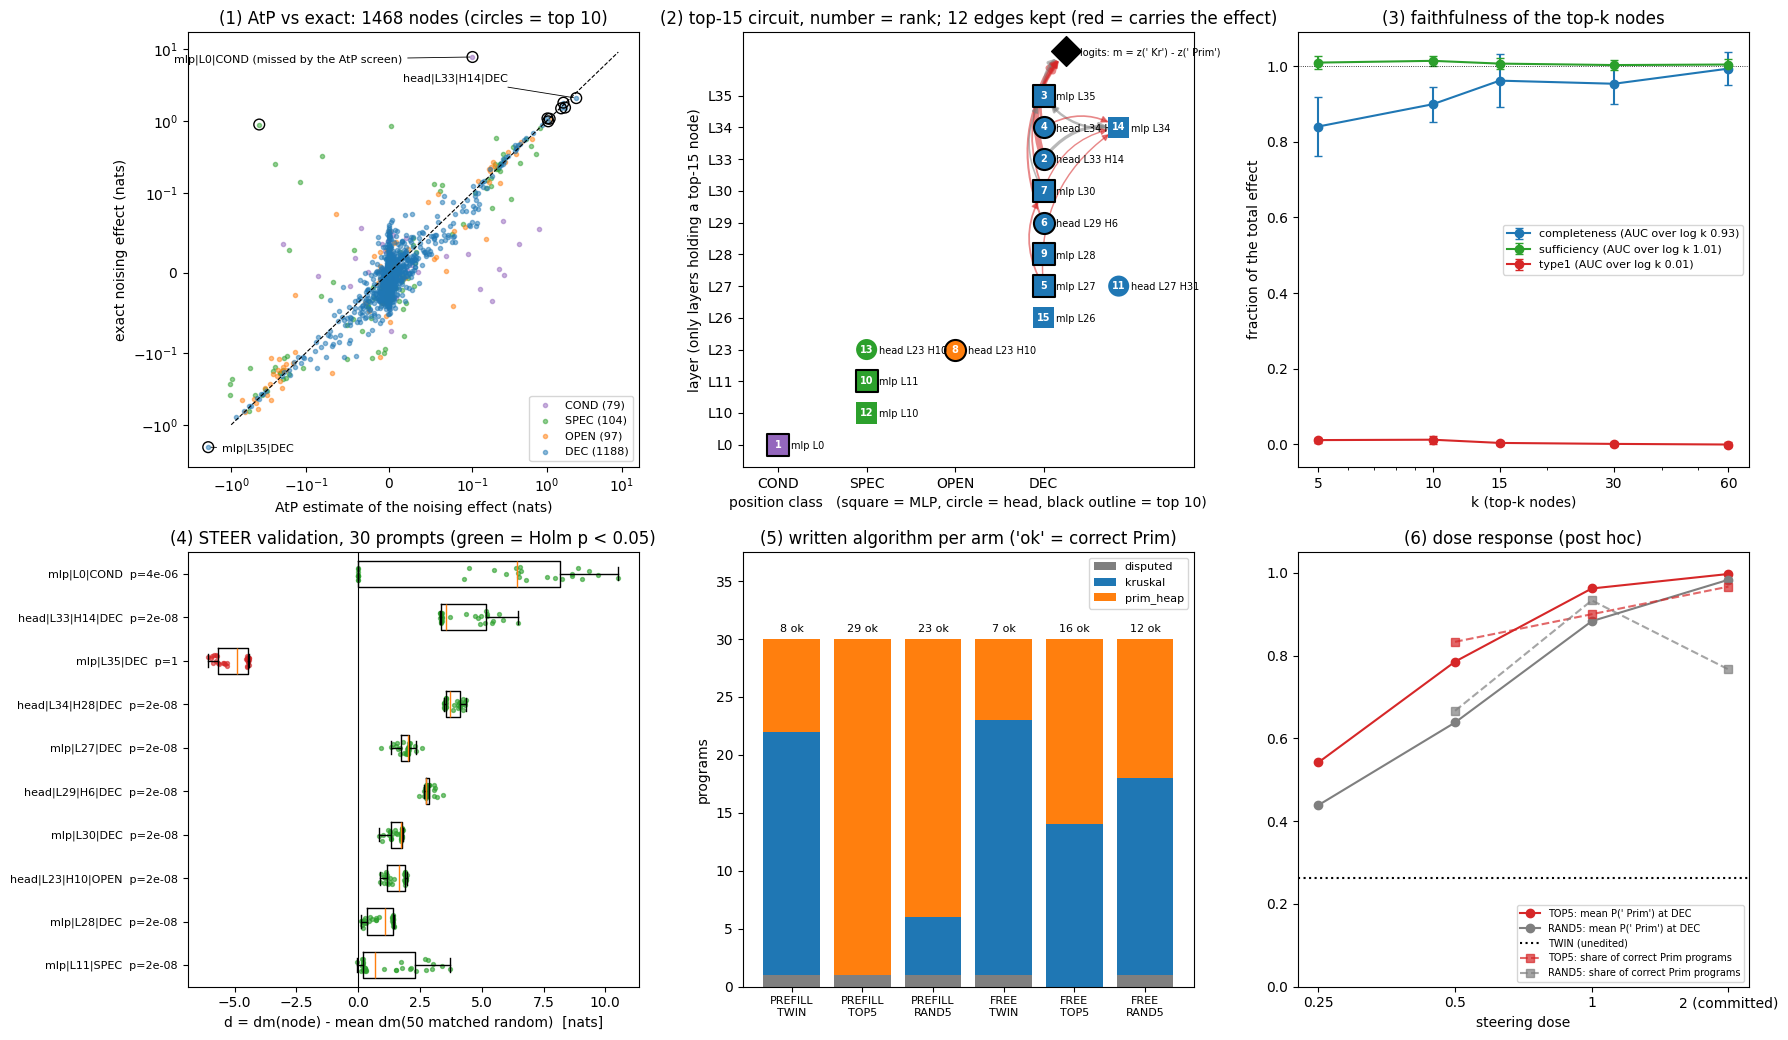

In [22]:
CLS_COL = {"COND": "tab:purple", "SPEC": "tab:green", "OPEN": "tab:orange", "DEC": "tab:blue"}
fig, axs = plt.subplots(2, 3, figsize=(18, 10.5))

# (1) AtP estimate vs exact noising effect over every exact-noised node
ax = axs[0, 0]
rows_all = {r["node"]: r for r in res_c["exact"] + res_c["exact_extended"]}
for r in res_c["reliability_rows"]:
    rows_all.setdefault(r["node"], r)
for cl in CLASSES:
    pts = [(r["atp_mean"], r["noise_mean"]) for k, r in rows_all.items() if k.endswith(cl)]
    ax.scatter(*zip(*pts), s=9, alpha=0.5, color=CLS_COL[cl], label=f"{cl} ({len(pts)})")
for k in res_c["top10"]:
    r = rows_all[k]
    ax.scatter(r["atp_mean"], r["noise_mean"], s=60, facecolors="none", edgecolors="k")
for k, txt, off in ((res_c["top10"][0], " (missed by the AtP screen)", (-215, -4)),
                    (res_c["top10"][1], "", (-125, 12)), (res_c["top10"][2], "", (10, -3))):
    r = rows_all[k]
    ax.annotate(f"{k.replace('|H-1', '')}{txt}", (r["atp_mean"], r["noise_mean"]), fontsize=8, xytext=off,
                textcoords="offset points", arrowprops=dict(arrowstyle="-", lw=0.6, color="k"))
lim = [-1, 9]
ax.plot(lim, lim, "k--", lw=0.8)
ax.set_xscale("symlog", linthresh=0.1)
ax.set_yscale("symlog", linthresh=0.1)
ax.set_xlabel("AtP estimate of the noising effect (nats)")
ax.set_ylabel("exact noising effect (nats)")
ax.set_title(f"(1) AtP vs exact: {len(rows_all)} nodes (circles = top 10)")
ax.legend(fontsize=8, loc="lower right")

# (2) the circuit: top-15 nodes by position class (x) and layer (y, only the layers that hold a node),
#     with the path-patching edges that pass the threshold; the number in each marker is the node's rank
ax = axs[0, 1]
layers = sorted({int(k.split("|")[1][1:]) for k in res_c["top15"]})
yl = {L: i for i, L in enumerate(layers)}
xcl = {cl: i for i, cl in enumerate(CLASSES)}
pos, cnt = {}, {}
for k in res_c["top15"]:
    kind, L, H, cl = k.split("|")
    n = cnt[(cl, L)] = cnt.get((cl, L), -1) + 1
    pos[k] = (xcl[cl] + 0.85 * n, yl[int(L[1:])])
pos["logits(m)"] = (xcl["DEC"] + 0.25, len(layers) + 0.4)
wmax = max(abs(e["effect_mean"]) for e in res_c["edges_kept"])
for e in res_c["edges_kept"]:
    if e["sender"] in pos and e["receiver"] in pos:
        (x0, y0), (x1, y1) = pos[e["sender"]], pos[e["receiver"]]
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), arrowprops=dict(
            arrowstyle="-|>", lw=0.5 + 4 * abs(e["effect_mean"]) / wmax, alpha=0.55, shrinkA=8, shrinkB=8,
            connectionstyle="arc3,rad=-0.3", color="tab:red" if e["effect_mean"] > 0 else "tab:gray"))
for i, k in enumerate(res_c["top15"]):
    (x, y), (kind, L, H, cl) = pos[k], k.split("|")
    ax.scatter(x, y, s=230, color=CLS_COL[cl], zorder=3, marker="s" if kind == "mlp" else "o",
               edgecolors="k" if k in res_c["top10"] else "none", linewidths=1.5)
    ax.text(x, y, str(i + 1), ha="center", va="center", fontsize=7, color="white", fontweight="bold", zorder=4)
    ax.annotate(f"{kind} {L}" + ("" if kind == "mlp" else f" {H}"), (x, y), xytext=(9, -3),
                textcoords="offset points", fontsize=7)
ax.scatter(*pos["logits(m)"], s=230, color="k", marker="D", zorder=3)
ax.annotate("logits: m = z(' Kr') - z(' Prim')", pos["logits(m)"], xytext=(10, -3), textcoords="offset points",
            fontsize=7)
ax.set_yticks(range(len(layers)), [f"L{L}" for L in layers])
ax.set_ylim(-0.7, len(layers) + 1)
ax.set_xticks(range(4), CLASSES)
ax.set_xlim(-0.4, 4.7)
ax.set_xlabel("position class   (square = MLP, circle = head, black outline = top 10)")
ax.set_ylabel("layer (only layers holding a top-15 node)")
ax.set_title(f"(2) top-15 circuit, number = rank; {len(res_c['edges_kept'])} edges kept (red = carries the effect)")

# (3) faithfulness curves
ax = axs[0, 2]
f = res_c["faithfulness"]
for key, col in (("completeness", "tab:blue"), ("sufficiency", "tab:green"), ("type1", "tab:red")):
    if f"{key}_mean" in f:
        m, s = np.array(f[f"{key}_mean"]), np.array(f[f"{key}_sd"])
        ax.errorbar(f["k"], m, yerr=s, marker="o", capsize=3, color=col,
                    label=f"{key} (AUC over log k {f[key + '_auc_logk']:.2f})")
ax.axhline(1, color="k", lw=0.6, ls=":")
ax.set_xscale("log")
ax.set_xticks(f["k"], [str(k) for k in f["k"]])
ax.set_xlabel("k (top-k nodes)")
ax.set_ylabel("fraction of the total effect")
ax.set_title("(3) faithfulness of the top-k nodes")
ax.legend(fontsize=8)

# (4) validation: per-prompt d for STEER, node minus mean of its matched random components
ax = axs[1, 0]
recs = vs["per_node"]["steer"]
ax.boxplot([r["d_per_prompt"] for r in recs], vert=False, widths=0.6, showfliers=False)
for i, r in enumerate(recs):
    ax.scatter(r["d_per_prompt"], np.full(len(r["d_per_prompt"]), i + 1) + np.random.default_rng(i).uniform(
        -0.15, 0.15, len(r["d_per_prompt"])), s=8, alpha=0.6, color="tab:green" if r["p_holm_20"] < 0.05 else "tab:red")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(range(1, len(recs) + 1), [f"{r['node'].replace('|H-1', '')}  p={r['p_holm_20']:.1g}" for r in recs],
              fontsize=8)
ax.invert_yaxis()
ax.set_xlabel(f"d = dm(node) - mean dm({N_RAND} matched random)  [nats]")
ax.set_title(f"(4) STEER validation, {vs['n_prompts']} prompts (green = Holm p < 0.05)")

# (5) generation labels per arm and condition
ax = axs[1, 1]
labs_all = sorted({l for r in gs.values() for a in r["arms"].values() for l in a["labels"]})
lab_col = {"kruskal": "tab:blue", "prim_heap": "tab:orange", "prim_array": "tab:brown", "disputed": "tab:gray",
           "other": "tab:pink"}
bars = [(c, a) for c in gs for a in ("TWIN", "TOP5", "RAND5") if a in gs[c]["arms"]]
bottom = np.zeros(len(bars))
for l in labs_all:
    v = np.array([gs[c]["arms"][a]["labels"].get(l, 0) for c, a in bars])
    ax.bar(range(len(bars)), v, bottom=bottom, color=lab_col.get(l, "k"), label=l)
    bottom += v
for i, (c, a) in enumerate(bars):
    ax.text(i, bottom[i] + 0.02 * bottom.max(), f"{gs[c]['arms'][a]['correct_target']} ok", ha="center", fontsize=8)
ax.set_ylim(0, bottom.max() * 1.25)
ax.set_xticks(range(len(bars)), [f"{c}\n{a}" for c, a in bars], fontsize=8)
ax.set_ylabel("programs")
ax.set_title("(5) written algorithm per arm ('ok' = correct Prim)")
ax.legend(fontsize=8)

# (6) dose response: logit level and generation
ax = axs[1, 2]
lp = ds["logit_p_minority_mean"]
for arm, col in (("TOP5", "tab:red"), ("RAND5", "tab:gray")):
    d_ = sorted(lp[arm], key=float)
    ax.plot([float(x) for x in d_], [lp[arm][x] for x in d_], marker="o", color=col, label=f"{arm}: mean P(' Prim') at DEC")
ax.axhline(ds["logit_twin_p_minority_mean"], color="k", ls=":", label="TWIN (unedited)")
n_gen = pre["arms"]["TOP5"]["n"]
gx = sorted(float(d) for d in ds["doses"]) + [STEER_DOSE]
for arm, col in (("TOP5", "tab:red"), ("RAND5", "tab:gray")):
    gy = [ds["doses"][str(d)][f"{arm}_correct_target"] / ds["doses"][str(d)]["n"] for d in gx[:-1]] + \
         [pre["arms"][arm]["correct_target"] / n_gen]
    ax.plot(gx, gy, marker="s", ls="--", color=col, alpha=0.7, label=f"{arm}: share of correct Prim programs")
ax.set_xscale("log", base=2)
ax.set_xticks([0.25, 0.5, 1, 2], ["0.25", "0.5", "1", "2 (committed)"])
ax.set_ylim(0, 1.05)
ax.set_xlabel("steering dose")
ax.set_title("(6) dose response (post hoc)")
ax.legend(fontsize=7, loc="lower right")

plt.tight_layout()
plt.show()

### One CRN slot, before and after steering

This is the same prompt with the same sampling uniforms. Without an edit, the model writes Kruskal. Steering five
components at the single decision position makes it write Prim. Both programs pass the hidden tests.

In [23]:
ex = next((e for e in examples if e["metadata_condition"] == "PREFILL" and e["predict_TWIN"].startswith("kruskal")
           and e["predict_TOP5"].startswith("prim")), examples[0])
print(f"slot {ex['metadata_template']}|{ex['metadata_slot']} ({ex['metadata_condition']}); prompt ends with:")
print("   ..." + ex["input"][-260:].replace("\n", "\n   "))
for arm in ("TWIN", "TOP5", "RAND5"):
    code_ = ex[f"metadata_{arm}_code"]
    print(f"\n===== {arm}: {ex[f'predict_{arm}']} =====")
    print(code_[:900] + ("\n    ..." if len(code_) > 900 else ""))

slot W1|1 (PREFILL); prompt ends with:
   ....<|im_end|>
   <|im_start|>assistant
   <think>
   
   </think>
   
   ```python
   def solve(n, roads):
       import heapq
   
       # Build adjacency list
       graph = [[] for _ in range(n)]
       for u, v, w in roads:
           graph[u].append((v, w))
           graph[v].append((u, w))
   
       #

===== TWIN: kruskal|pass =====
def solve(n, roads):
    import heapq

    # Build adjacency list
    graph = [[] for _ in range(n)]
    for u, v, w in roads:
        graph[u].append((v, w))
        graph[v].append((u, w))

    # Kruskal's algorithm using Union-Find
    parent = list(range(n))

    def find(u):
        while parent[u] != u:
            parent[u] = parent[parent[u]]
            u = parent[u]
        return u

    def union(u, v):
        root_u = find(u)
        root_v = find(v)
        if root_u == root_v:
            return False
        parent[root_v] = root_u
        return True

    # Sort roads by weight
    sorted_r

## Takeaways and how to run the full pipeline

* **Node level: supported.** 9 of the 10 top components beat 50 norm-matched random components of the same type and
  position in both ablation and steering (Holm over 20). The node that fails, `mlp|L35|DEC`, works *against* the
  decision; it acts as a brake.
* **Generation: partially supported.** Steering the top five components at the decision position rewrites the
  written algorithm: 29/30 correct Prim programs, against 8/30 for the unedited twin, with pass rates unchanged. At
  the committed dose of 2, however, the matched random five also flips 23/30. The pre-registered two-sided McNemar
  (7:1, p = 0.070) misses, so the C1 verdict is **PARTIAL** (it would be PASS with the one-sided test the code fixed
  at commit #0).
* **Mechanism.** A layer-0 MLP at the instruction span injects the instruction, and a late stack of
  decision-position heads and MLPs (layers 23-35) turns it into the decision logit. The first-order AtP screen missed
  the injecting MLP; only the exhaustive exact sweep found it.

**Full run (GPU).** The complete pipeline needs the artifact repository (`method.py`, `src/`, `inputs/`), Qwen3-8B at
revision `b968826d`, and a GPU with at least 20 GB of memory (the original ran on an NVIDIA L4 with 23 GB):

```bash
uv venv .venv --python=3.12 && uv pip install --python .venv/bin/python -r pyproject.toml
.venv/bin/python src/download_model.py
.venv/bin/python method.py --stages setup,contrasts,gputests,amend0a,circuit:C1forced,circuit:C2a,circuit:C1nat,circuit:C1mix
.venv/bin/python method.py --stages f4b:C1forced,f4b:C2a,commit1:C1forced+C2a,validate:C1forced,validate:C2a,commit2:C1forced+C2a,gen:C1forced,gen:C2a,enginecheck
.venv/bin/python method.py --stages valsens:C1forced,valsens:C2a,f4b:C1nat,commit1b:C1nat,validate:C1nat,circuitlite:C1natB,f4b:C1natB,dose:C1forced,dose:C2a
```

The CPU functions replayed here are the same ones those stages call.